In [176]:
### Check Remote-other 44 to inward arrow (Smallholders)

In [1]:
Landuse_map = 'Mapbiomas'

In [2]:
import xarray as xr
import numpy as np
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy

from matplotlib.sankey import Sankey

/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


In [3]:
LU_Mapbiomas_forest = xr.open_dataset('/home/chandra/data/Paper4/Data_previous_literature/Mapbiomas_LU_forest.tif').band_data[0,::-1]
LU_Mapbiomas_forest['x'] = LU_Mapbiomas_forest.x.values%360
LU_Mapbiomas_forest = LU_Mapbiomas_forest.sortby('x')
#LU_Mapbiomas = LU_Mapbiomas.sel(y = slice(-45, 15), x = slice(270, 330))
LU_Mapbiomas_forest = LU_Mapbiomas_forest.sel(y = slice(-39.25, 10.25), x = slice(280, 330))

In [4]:
Stakeholder = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc')[0,::-1,:-1]
Stakeholder['x'] = Stakeholder.x.values%360

/tmp/ipykernel_4155476/3478874843.py:1: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Stakeholder = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc')[0,::-1,:-1]


Text(0.5, 1.0, 'Forest')

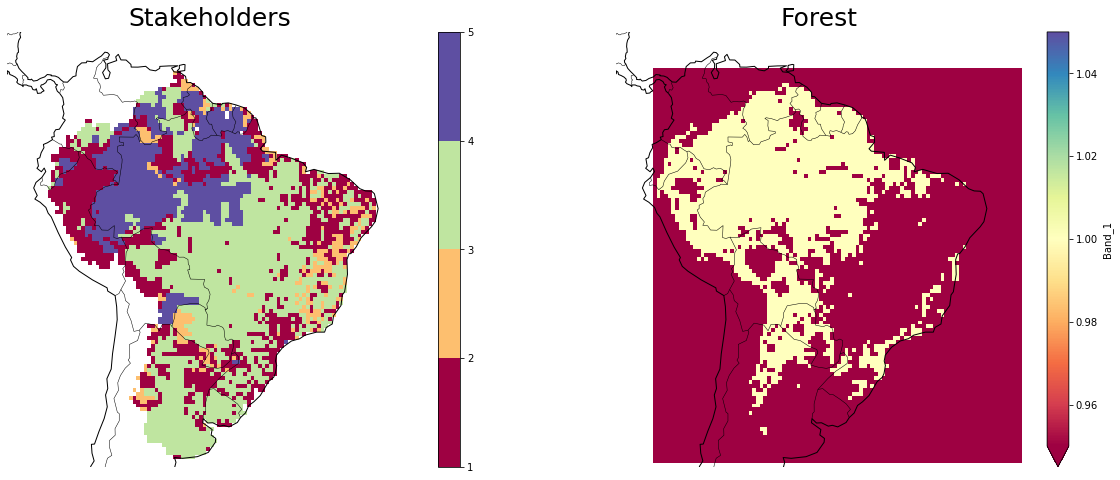

In [5]:
fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]
Stakeholder.plot(ax = ax[0], cmap = 'Spectral', levels = [1,2,3,4,5])
LU_Mapbiomas_forest.plot(ax = ax[1], vmin = 1, vmax = 1, cmap = 'Spectral')

for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    
ax[0].set_title('Stakeholders', fontsize = '25')
ax[1].set_title('Forest', fontsize = '25')

In [6]:
stakeholder = 'Smallholders'

Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+Landuse_map+'.nc').Evap_footprint[:,::-1].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,:-1].sum(dim = 'month')
Water_footprint = Water_footprint.sel(lat = slice(-39.25,10.25), lon = slice(280,330))
Water_footprint = Water_footprint.where(Stakeholder.values>0)
#Water_footprint = (Water_footprint*(50*50)/1000000)

a = []
a.append(np.nansum(Water_footprint.values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 1).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 2).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 3).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 4).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 5).values))
#a.append(-(a[0]+(a[1]+a[2]+a[3]+a[4]+a[5])))
print(a)

b = []
for i in [1,2,3,4,5]:
    b.append(np.nansum(Water_footprint.where((LU_Mapbiomas_forest.values == 1) & (Stakeholder.values == i)).values))
b.append(-np.nansum(Water_footprint.where(LU_Mapbiomas_forest.values == 1).values))
print(b)

[1008590.0368940466, -368142.35465001286, -34409.668598874494, -369212.57399895444, -236736.40069105377, -89.03895515092165]
[199910.4894048177, 15518.603443203947, 143514.46418879204, 231094.9357130916, 44.28348931634303, -590082.7762392217]


In [7]:
### Smallholders-Mapbiomas

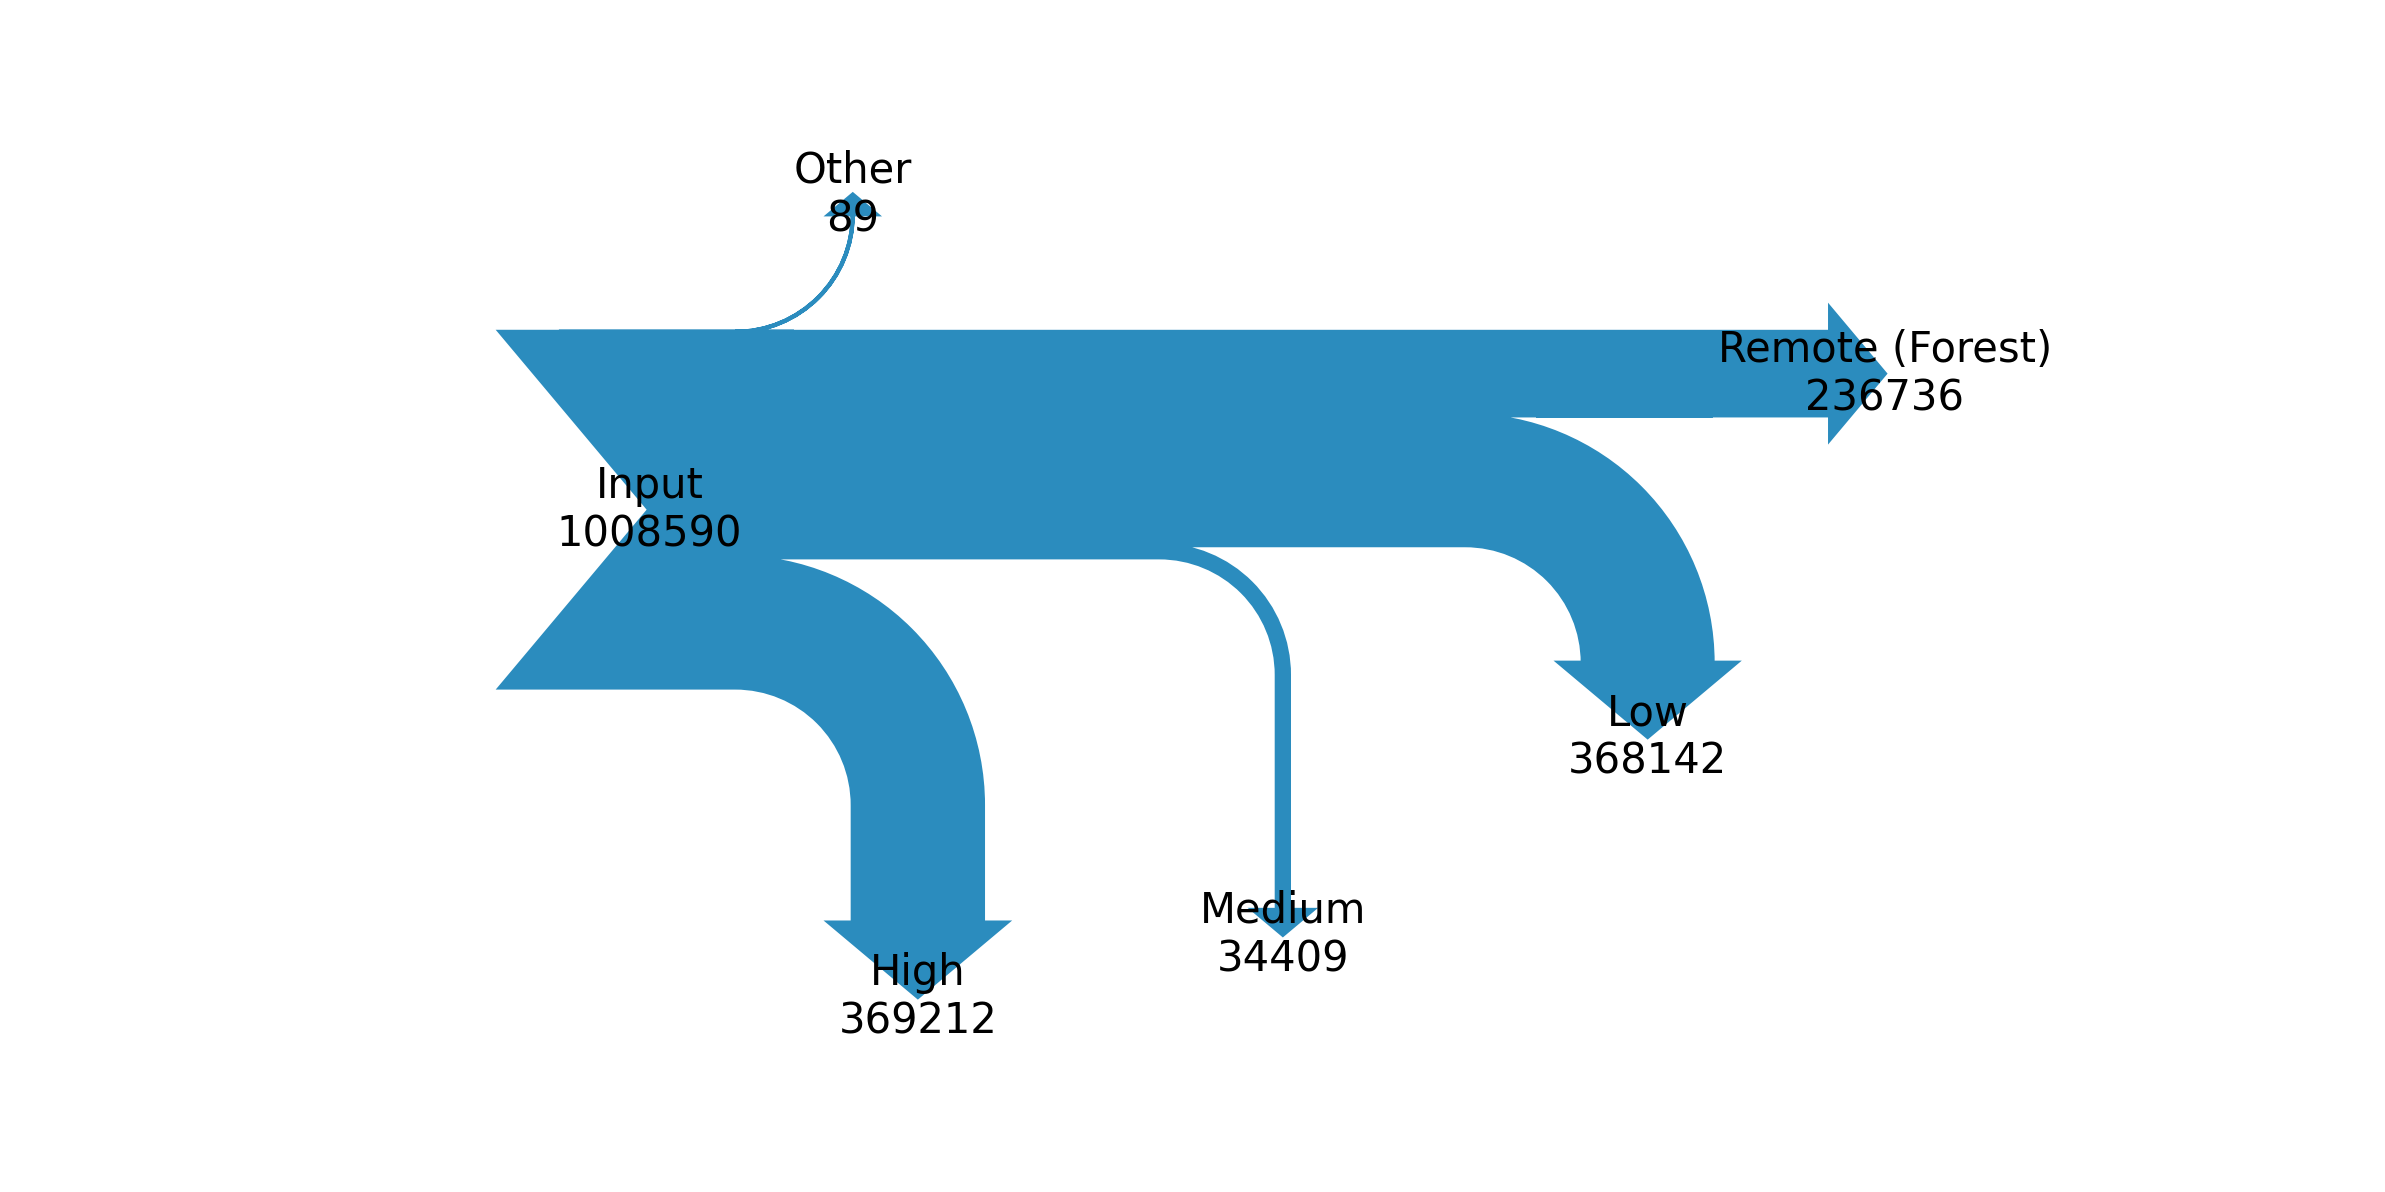

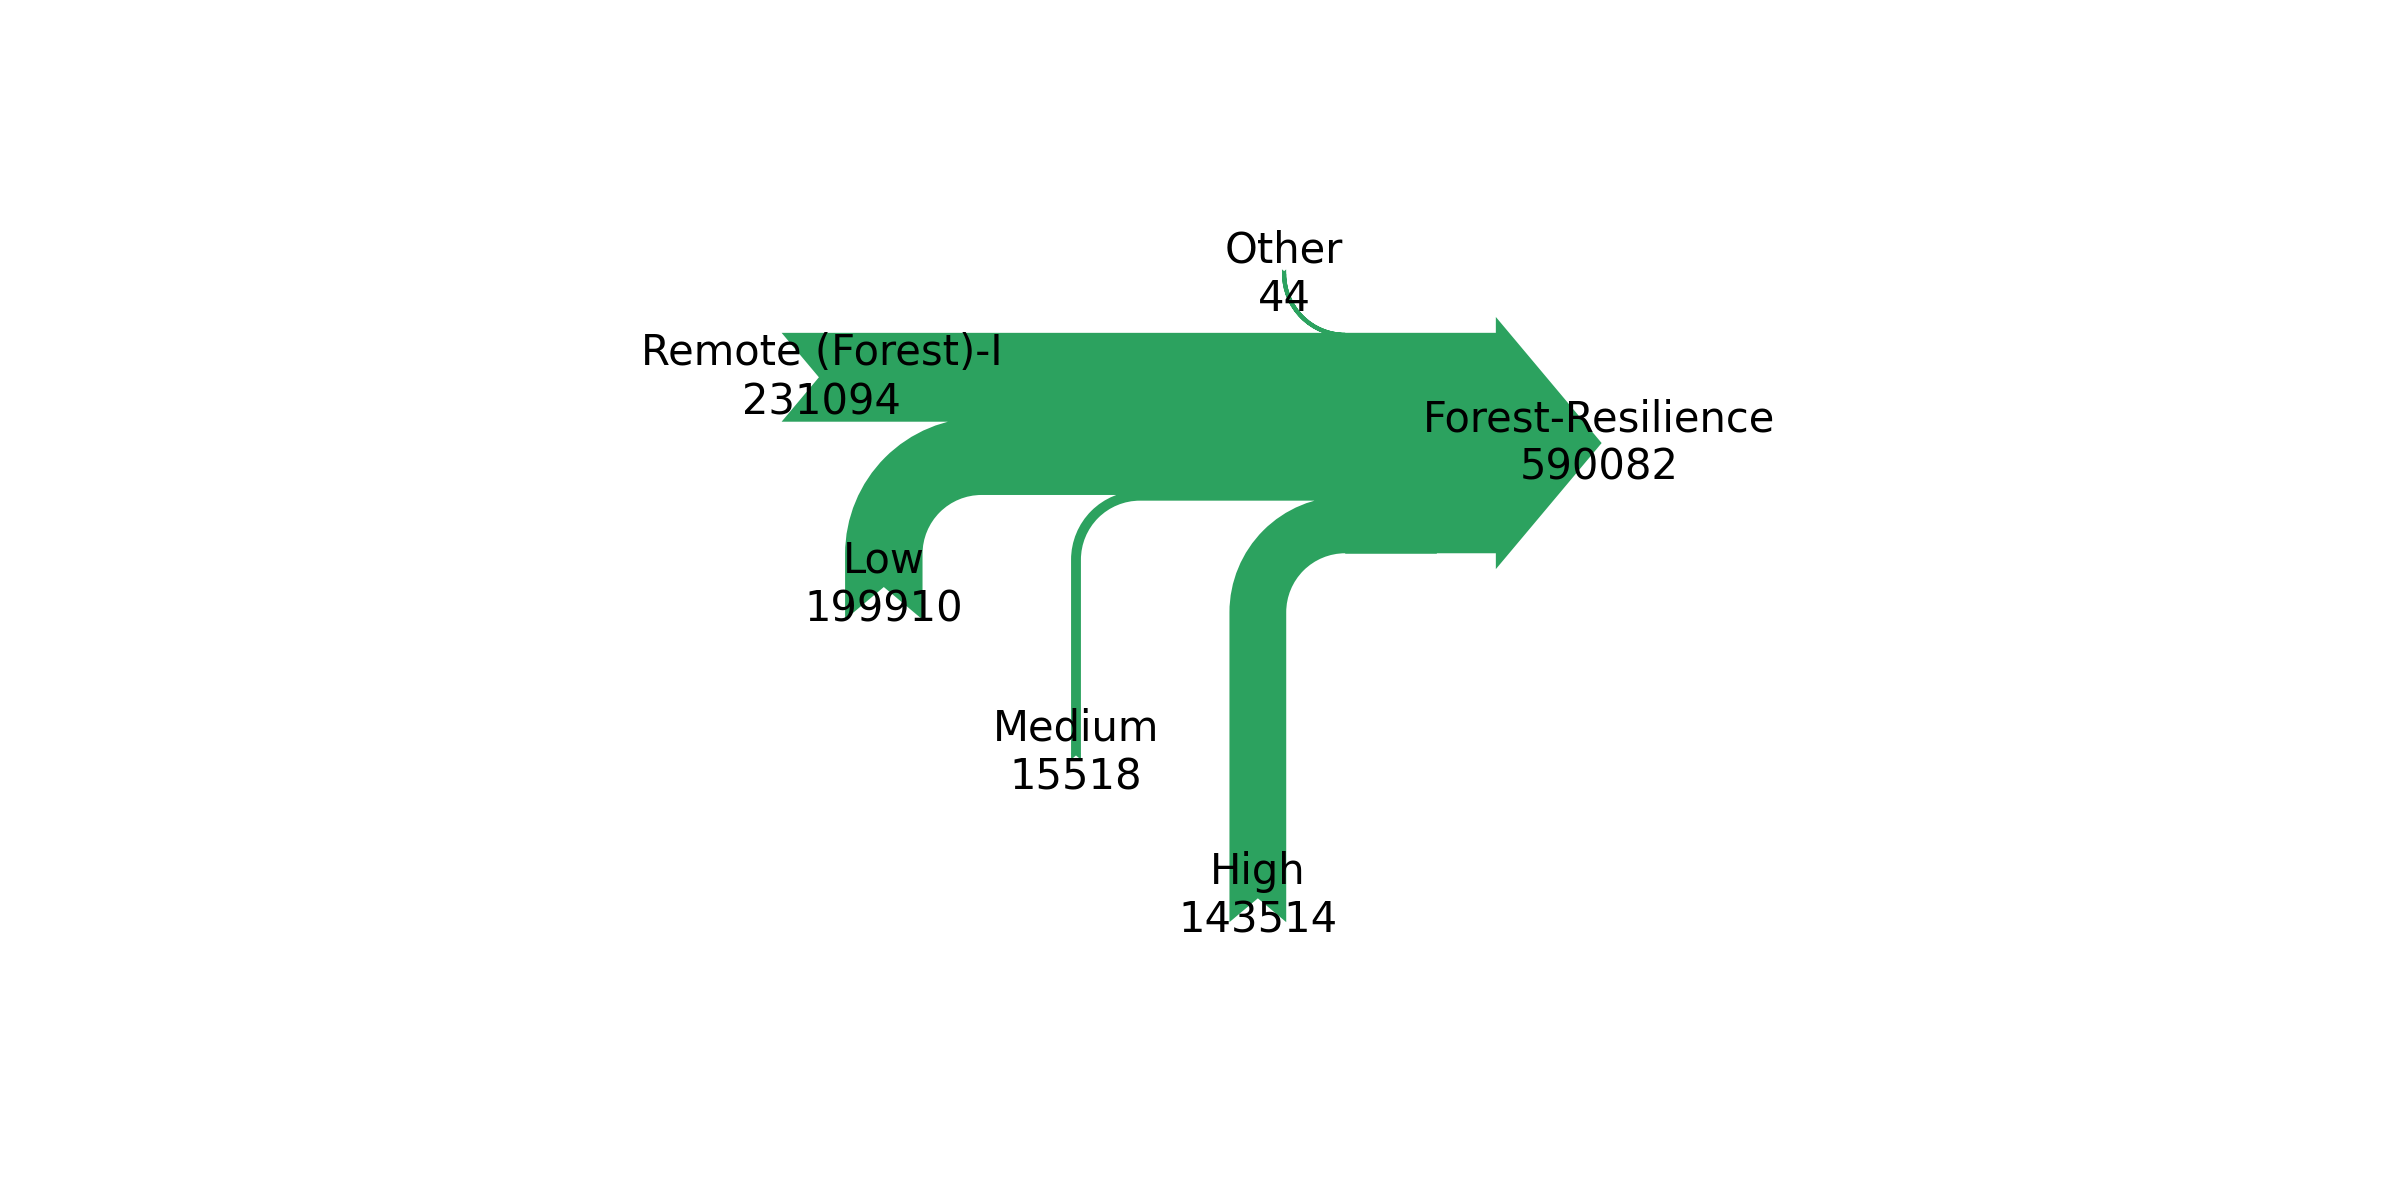

In [8]:
from matplotlib.sankey import Sankey
from matplotlib import pyplot as plt
fig = plt.figure(figsize = [10,5], dpi = 300)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000003, 
                offset= 0,
                format = '%d',shoulder = 0.02)

sankey.add(flows=a, 
           labels = ['Input', 'Low', 'Medium', 'High', 'Remote (Forest)', 'Other'], 
           orientations=[0, -1, -1, -1, 0, 1],#arrow directions,
           pathlengths = [0.05,0.1,0.3,0.2,0.1, 0.1],
           trunklength = 0.5,
           edgecolor = '#2b8cbe',
           facecolor = '#2b8cbe')

diagrams = sankey.finish()
for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()

fig = plt.figure(figsize = [10,5], dpi = 300)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000006, 
                offset= 0,
                format = '%d',shoulder = 0.02)

sankey.add(flows=b, 
           labels = ['Low', 'Medium', 'High', 'Remote (Forest)-I', 'Other', 'Forest-Resilience'], 
           orientations=[-1, -1, -1, 0, 1, 0],#arrow directions,
           pathlengths = [0.2,0.42,0.6,0.1,0.1,0.1],
           trunklength = 0.5, 
           connect = (4,3),
           edgecolor = '#2ca25f',
           facecolor = '#2ca25f')

diagrams = sankey.finish()
for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()

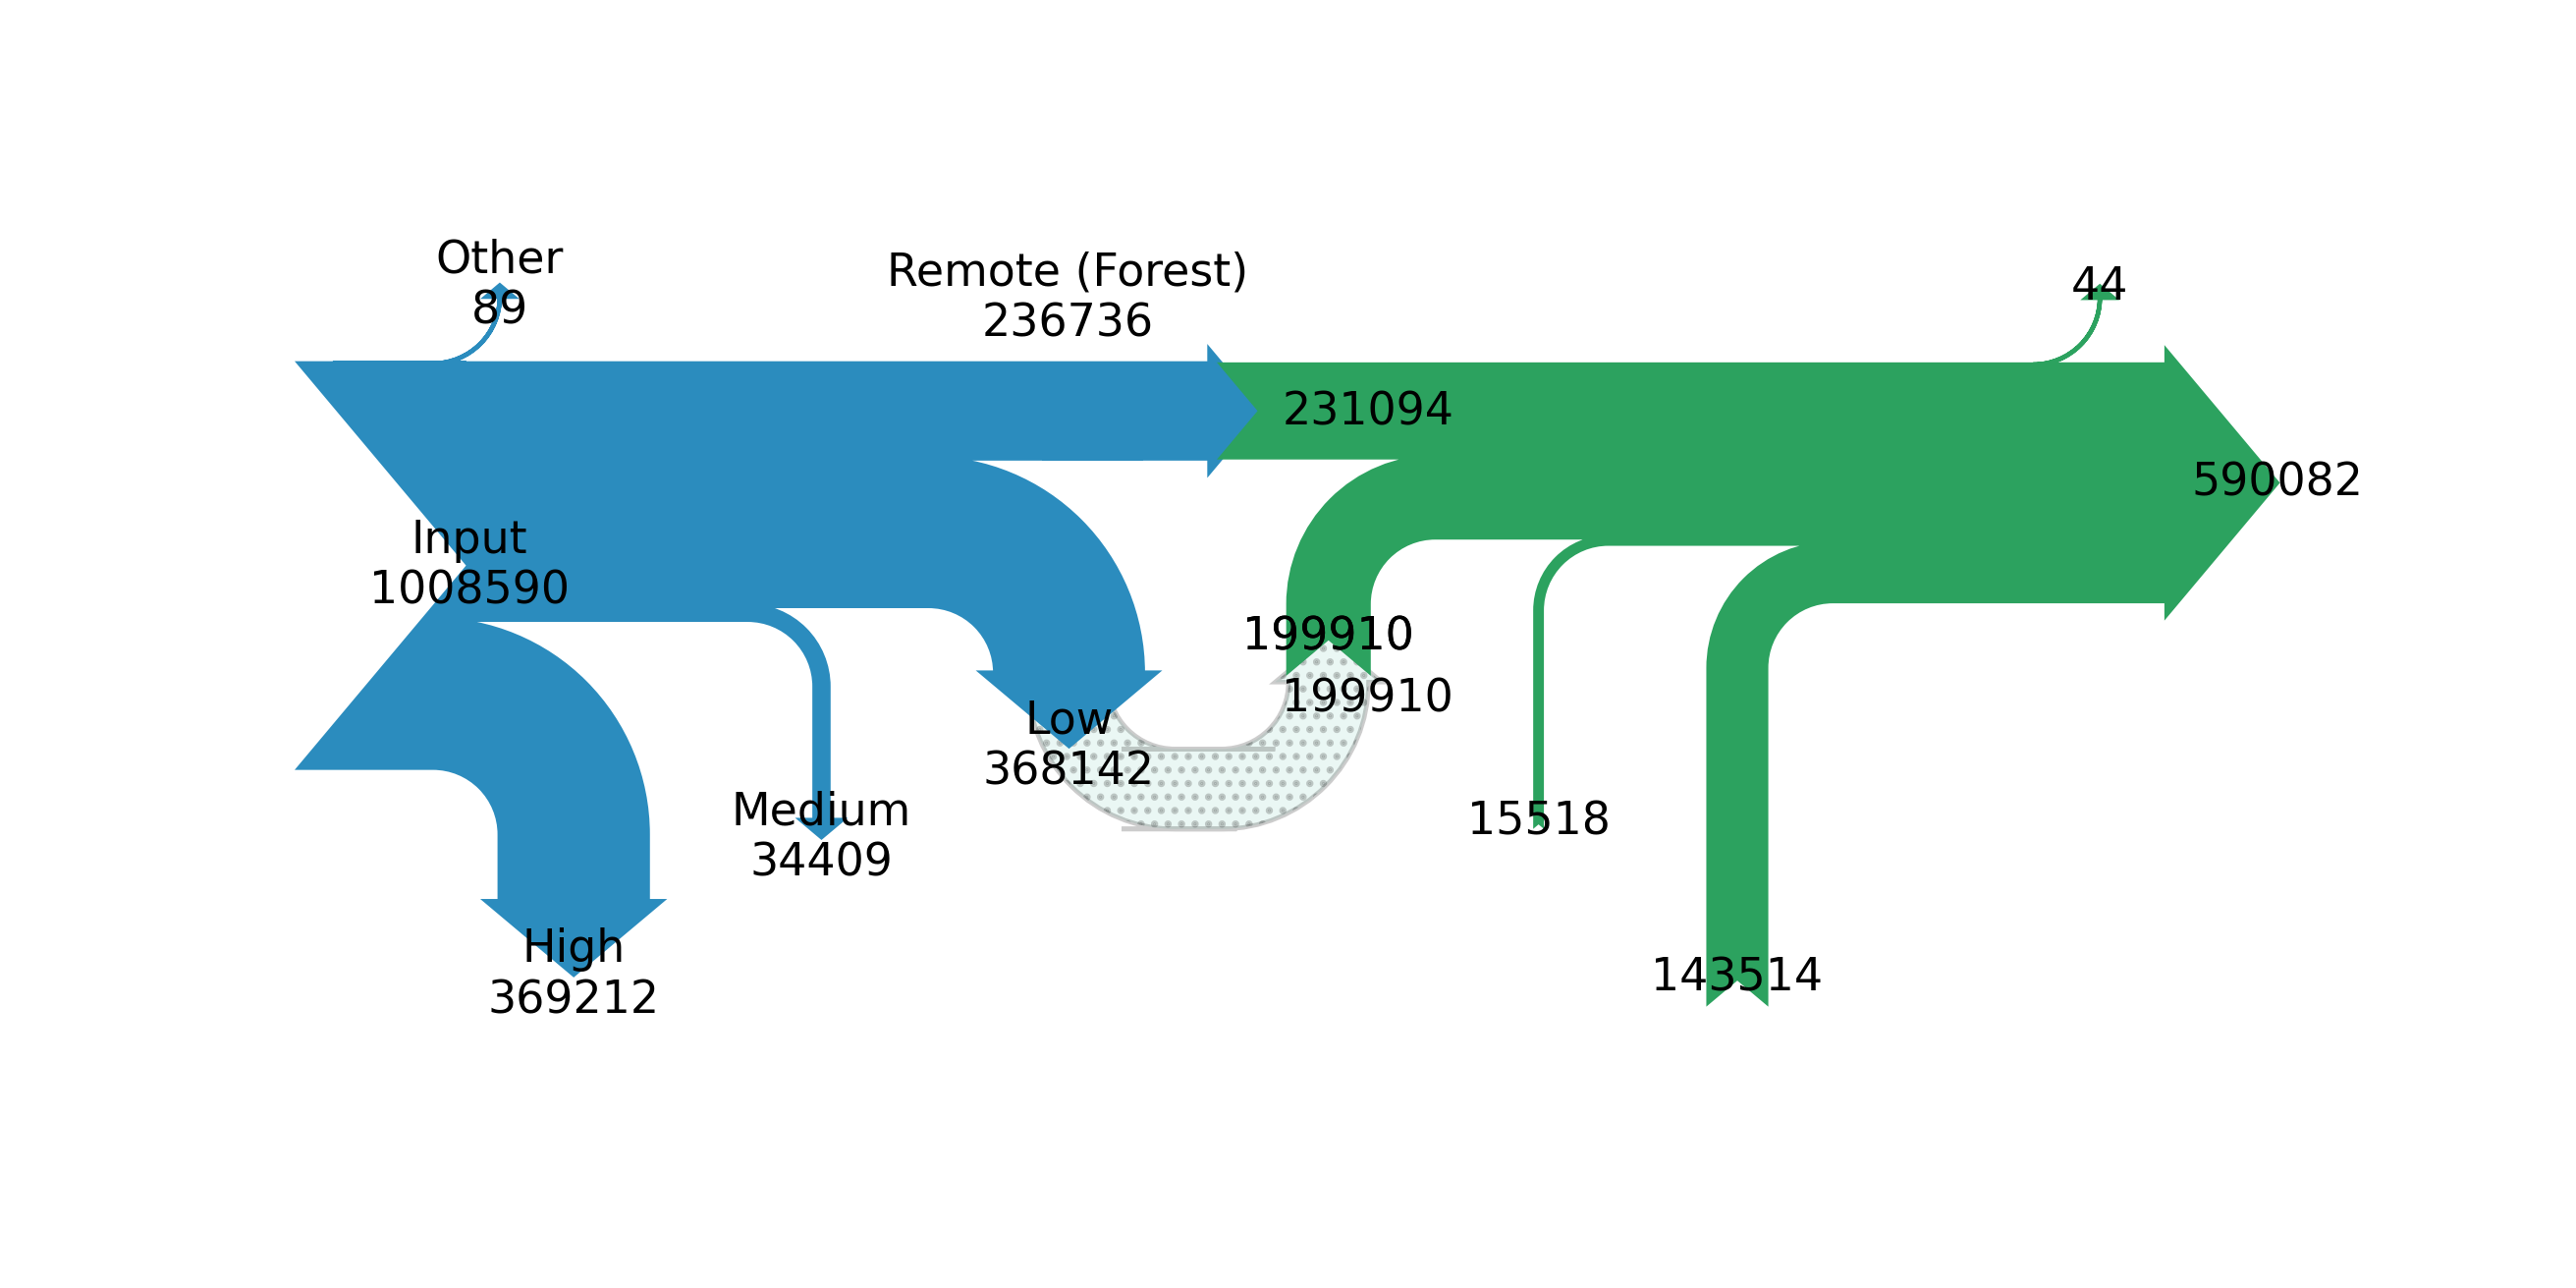

In [9]:
from matplotlib.sankey import Sankey
from matplotlib import pyplot as plt
fig = plt.figure(figsize = [10,5], dpi = 330)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000006, 
                offset= 0,
                format = '%d',shoulder = 0.02, tolerance=6000)

sankey.add(flows=a, 
           labels = ['Input', 'Low', 'Medium', 'High', 'Remote (Forest)', 'Other'], 
           orientations=[0, -1, -1, -1, 0, 1],#arrow directions,
           pathlengths = [0.05,0.1,0.3,0.2,0.1, 0.1],
           trunklength = 0.5,
           edgecolor = '#2b8cbe',
           facecolor = '#2b8cbe')

sankey.add(flows=b, 
           #labels = ['Low', 'Medium', 'High', 'Remote (Forest)-I', 'Other', 'Forest-Resilience'], 
           orientations=[-1, -1, -1, 0, 1, 0],#arrow directions,
           pathlengths = [0.2,0.42,0.6,0.1,0.1,0.1],
           trunklength = 0.5, 
           prior =0, connect = (4,3),
           edgecolor = '#2ca25f',
           facecolor = '#2ca25f')

sankey.add(flows=[b[0],-b[0]], 
           #labels = ['Low'], 
           orientations=[1, 1],#arrow directions,
           pathlengths = [0.1,0.1],
           trunklength = 0.27, 
           prior = 1, connect = (0,1),
           edgecolor = None,
           facecolor = '#99d8c9', hatch = '....', zorder = -2, label = 'False', alpha = 0.2)

diagrams = sankey.finish()
diagrams[0].texts[4].set_position(xy=[1.1, 0.4])
diagrams[1].texts[3].set_position(xy=[1.55, 0.23])
diagrams[2].texts[0].set_position(xy=[1.55,-0.2])

for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()

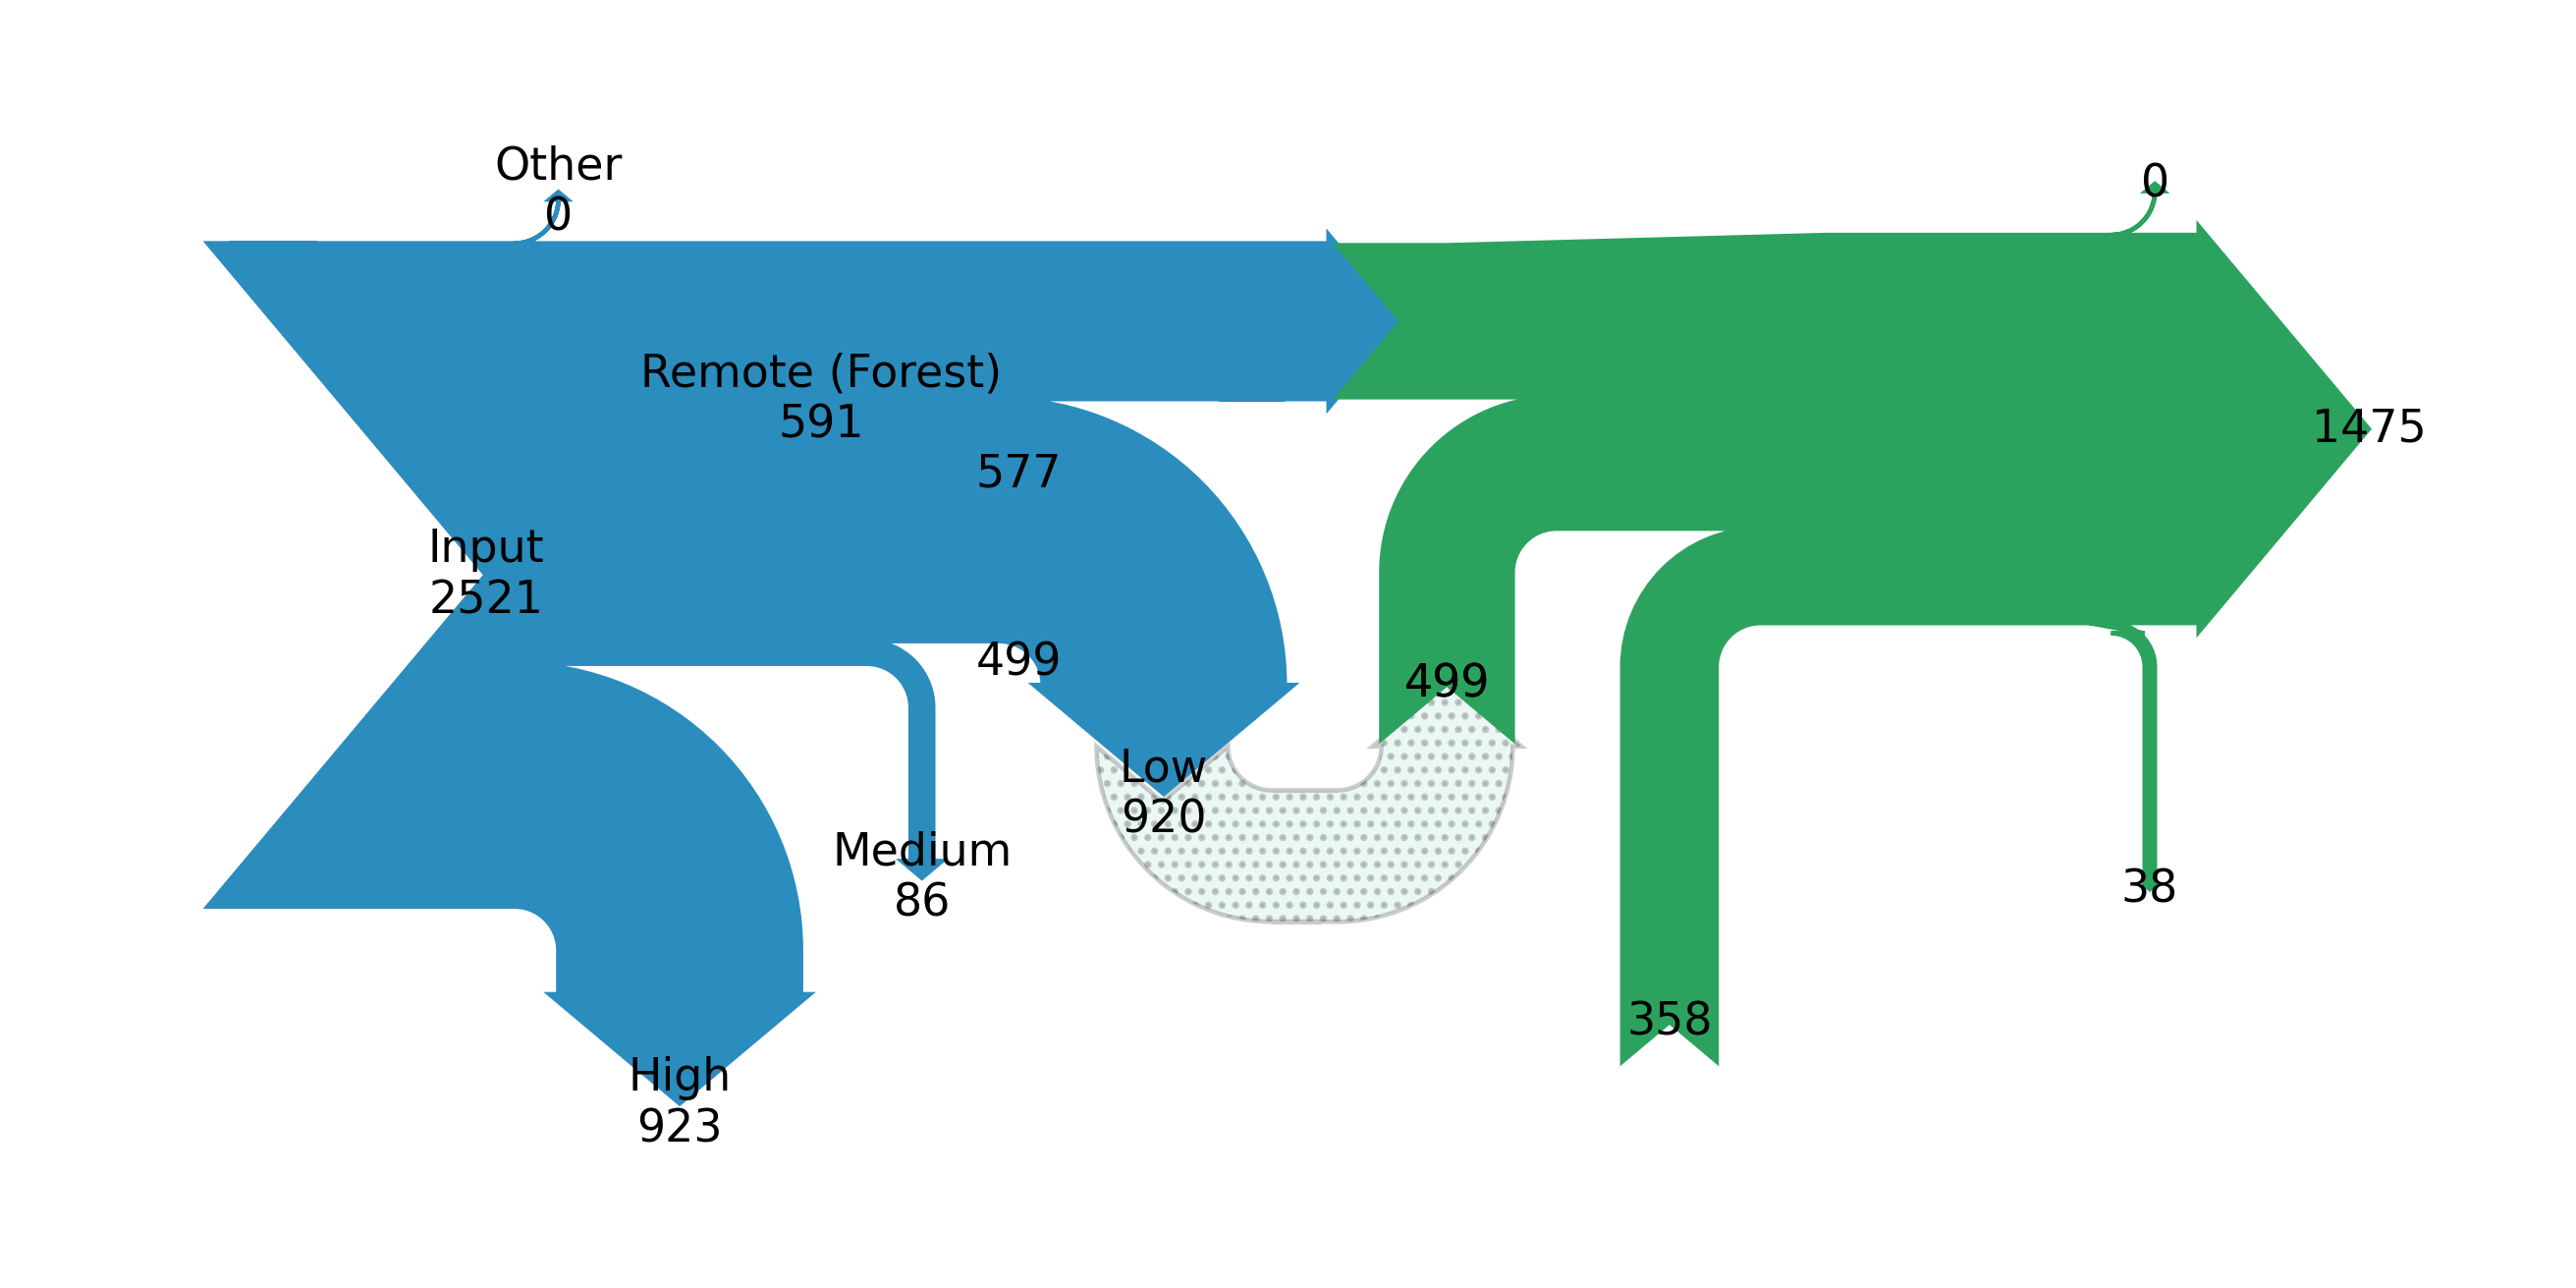

<Figure size 432x288 with 0 Axes>

In [98]:
from matplotlib.sankey import Sankey
from matplotlib import pyplot as plt
fig = plt.figure(figsize = [10,5], dpi = 330)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0006, 
                offset= 0,
                format = '%d',shoulder = 0.02, tolerance=100)

sankey.add(flows=a, 
           labels = ['Input', 'Low', 'Medium', 'High', 'Remote (Forest)', 'Other'], 
           orientations=[0, -1, -1, -1, 0, 1],#arrow directions,
           pathlengths = [0.05,0.1,0.45,0.2,0.1, 0.1],
           trunklength = 1,
           edgecolor = '#2b8cbe',
           facecolor = '#2b8cbe')

sankey.add(flows=b, 
           #labels = ['Low', 'Medium', 'High', 'Remote (Forest)-I', 'Other', 'Forest-Resilience'], 
           orientations=[-1, -1, -1, 0, 1, 0],#arrow directions,
           pathlengths = [0.48,0.6,1,0.1,0.1,0.1],
           trunklength = 1, 
           prior =0, connect = (4,3),
           edgecolor = '#2ca25f',
           facecolor = '#2ca25f')

sankey.add(flows=[b[0],-b[0]], 
           #labels = ['Low'], 
           orientations=[1, 1],#arrow directions,
           pathlengths = [0.1,0.1],
           trunklength = 0.35, 
           prior = 1, connect = (0,1),
           edgecolor = None,
           facecolor = '#99d8c9', hatch = '....', zorder = -2, label = 'False', alpha = 0.2)

diagrams = sankey.finish()
diagrams[0].texts[4].set_position(xy=[1.1, 0.4])
diagrams[1].texts[3].set_position(xy=[1.55, 0.23])
diagrams[2].texts[0].set_position(xy=[1.55,-0.2])

for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()
plt.tight_layout()

fig.savefig('/home/chandra/data/Paper4/Output/Moisture_flows_assessments/Moisture-Flows_'+stakeholder+'_'+Landuse_map+'.svg',bbox_inches="tight", dpi = 10)

In [35]:
## Mediumholders

In [57]:
stakeholder = 'Mediumholders'

Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+Landuse_map+'.nc').Evap_footprint[:,::-1].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,:-1].sum(dim = 'month')
Water_footprint = Water_footprint.sel(lat = slice(-39.25,10.25), lon = slice(280,330))
Water_footprint = Water_footprint.where(Stakeholder.values>0)

a = []
a.append(np.nansum(Water_footprint.values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 1).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 2).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 3).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 4).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 5).values))
#a.append(-(a[0]+(a[1]+a[2]+a[3]+a[4]+a[5])))
print(a)

b = []
for i in [1,2,3,4,5]:
    b.append(np.nansum(Water_footprint.where((LU_Mapbiomas_forest.values == 1) & (Stakeholder.values == i)).values))
b.append(-np.nansum(Water_footprint.where(LU_Mapbiomas_forest.values == 1).values))
print(b)

[203310.59063162454, -53286.93340365781, -14212.278735098069, -87559.05949053673, -48175.060480778746, -77.2585215531824]
[25427.441977411287, 5797.198550814293, 29504.88760835286, 47152.135499958946, 49.00579173333558, -107930.66942827072]


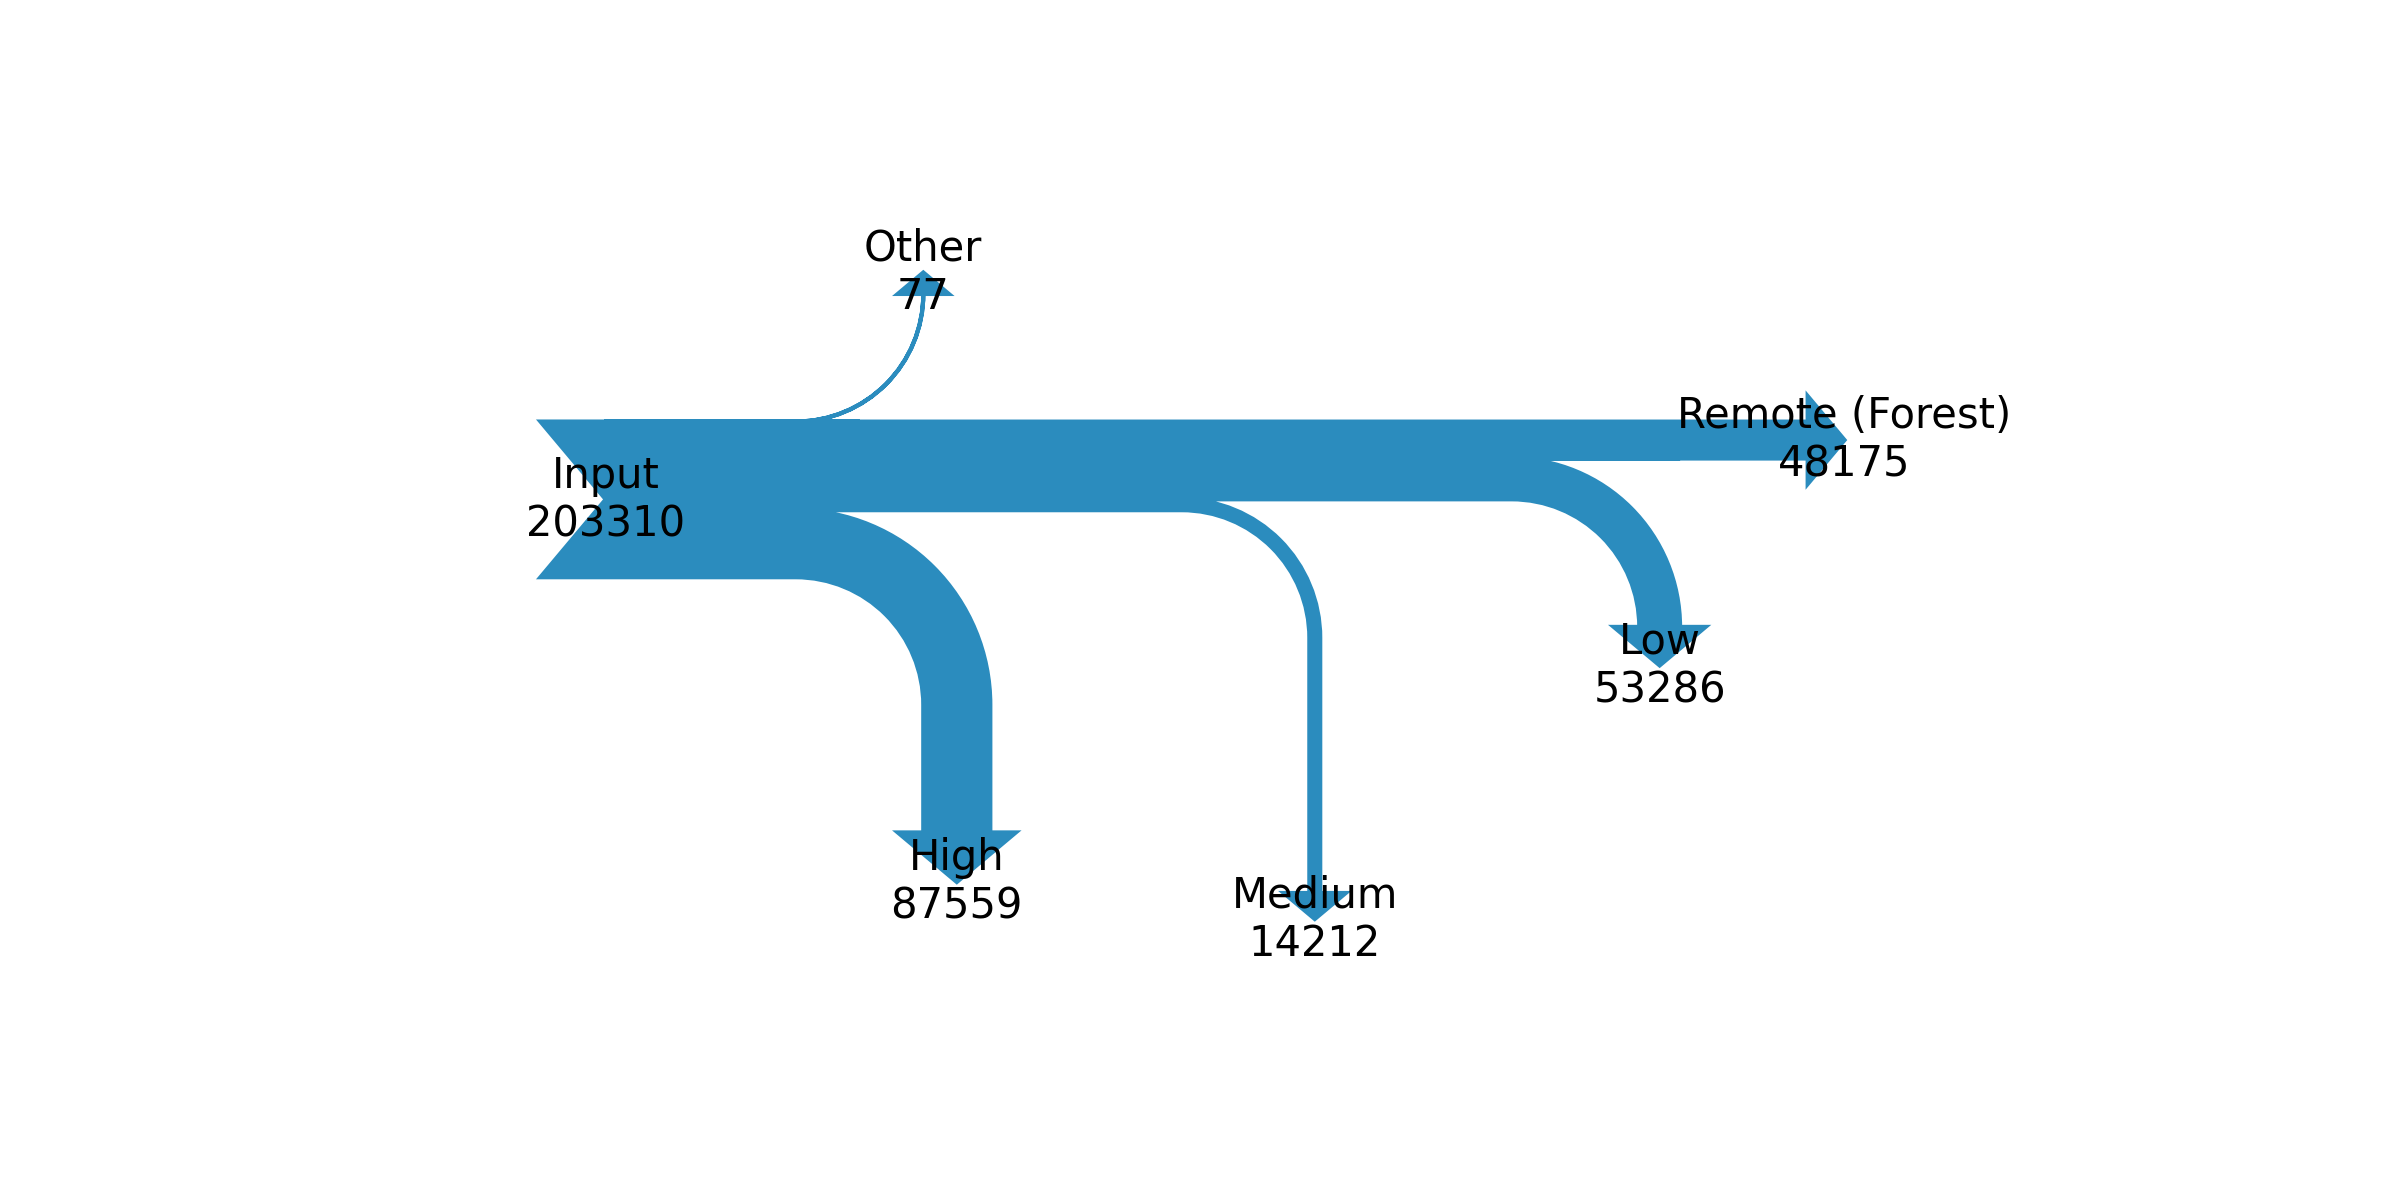

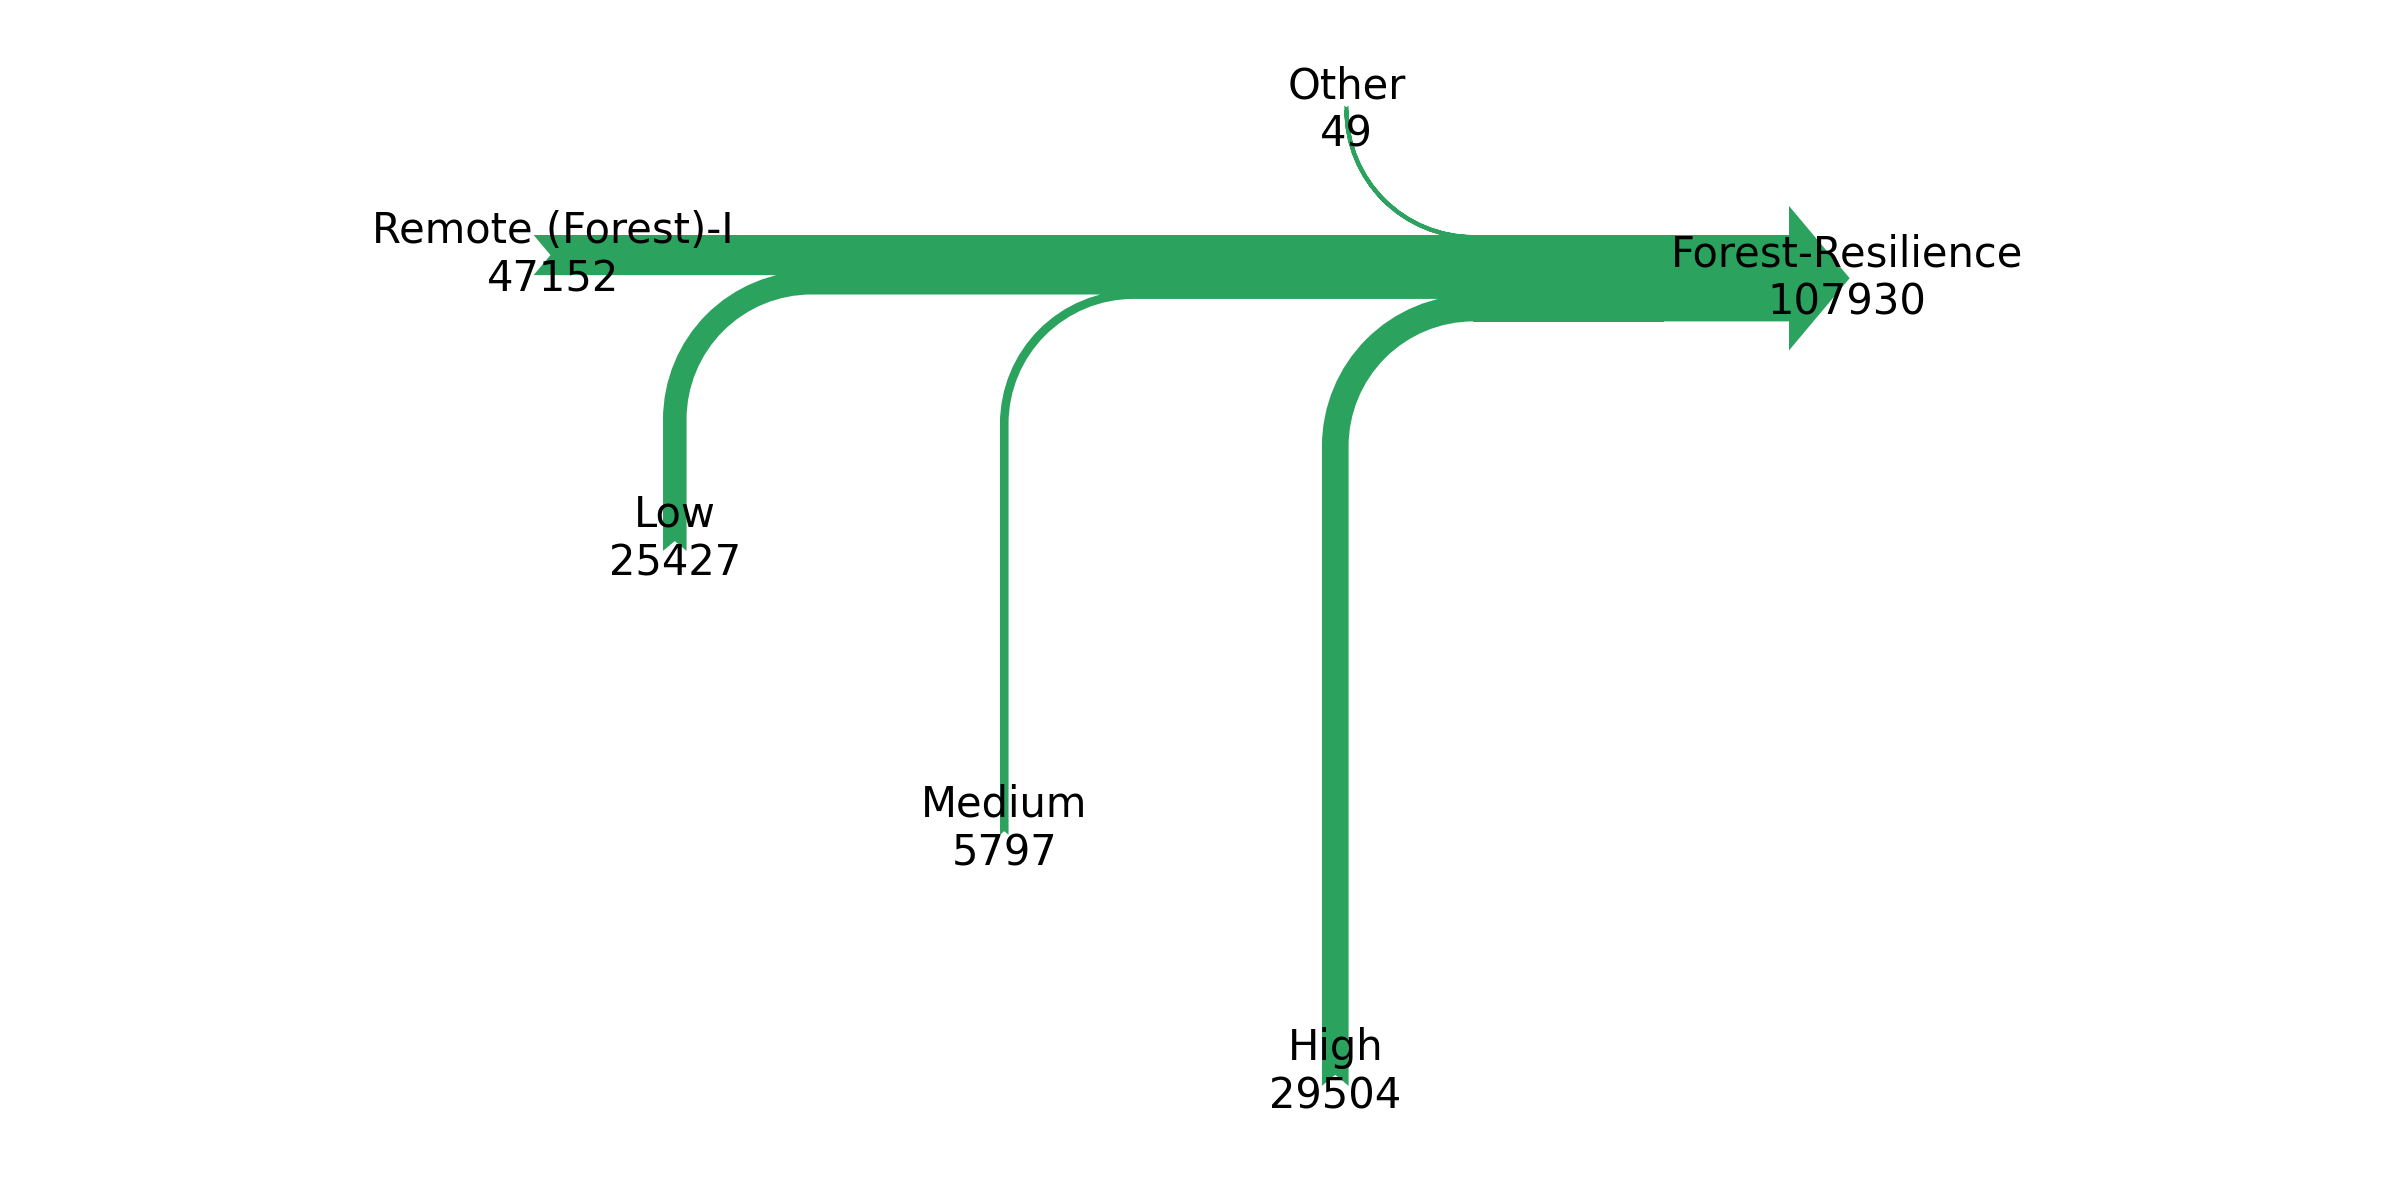

In [58]:
from matplotlib.sankey import Sankey
from matplotlib import pyplot as plt
fig = plt.figure(figsize = [10,5], dpi = 300)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000006, 
                offset= 0,
                format = '%d',shoulder = 0.02)

sankey.add(flows=a, 
           labels = ['Input', 'Low', 'Medium', 'High', 'Remote (Forest)', 'Other'], 
           orientations=[0, -1, -1, -1, 0, 1],#arrow directions,
           pathlengths = [0.05,0.1,0.3,0.2,0.1, 0.1],
           trunklength = 0.5,
           edgecolor = '#2b8cbe',
           facecolor = '#2b8cbe')

diagrams = sankey.finish()
for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()

fig = plt.figure(figsize = [10,5], dpi = 300)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000006, 
                offset= 0,
                format = '%d',shoulder = 0.02)

sankey.add(flows=b, 
           labels = ['Low', 'Medium', 'High', 'Remote (Forest)-I', 'Other', 'Forest-Resilience'], 
           orientations=[-1, -1, -1, 0, 1, 0],#arrow directions,
           pathlengths = [0.2,0.42,0.6,0.1,0.1,0.1],
           trunklength = 0.5, 
           connect = (4,3),
           edgecolor = '#2ca25f',
           facecolor = '#2ca25f')

diagrams = sankey.finish()
for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()

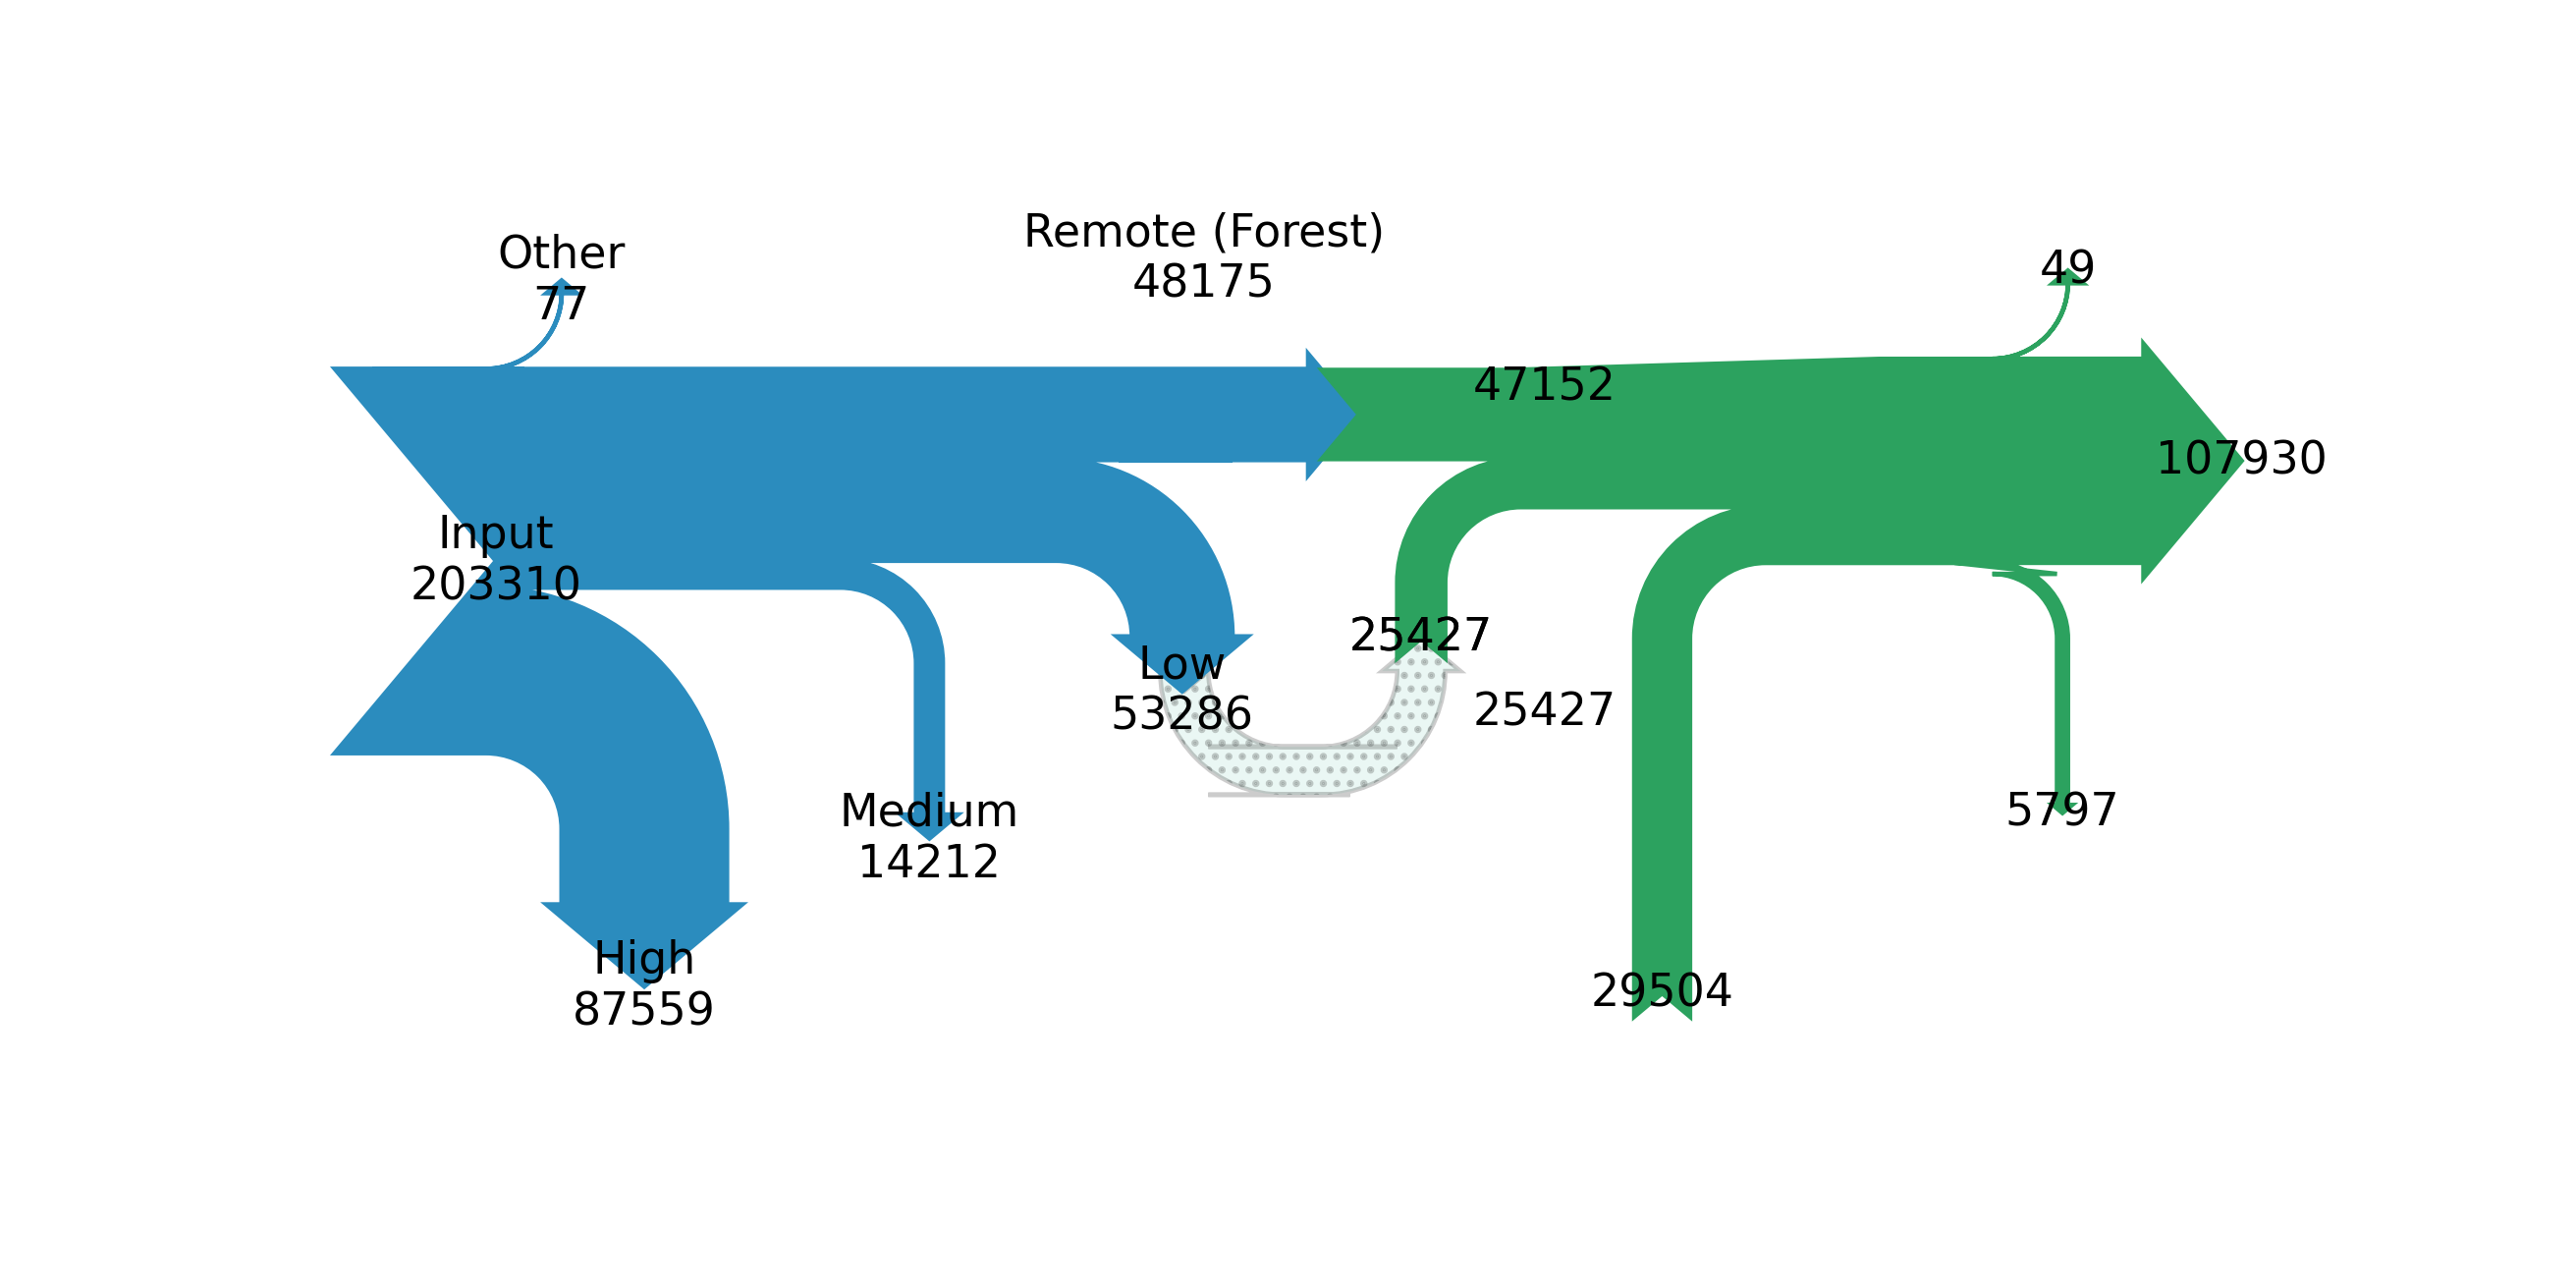

In [62]:
from matplotlib.sankey import Sankey
from matplotlib import pyplot as plt
fig = plt.figure(figsize = [10,5], dpi = 330)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000025, 
                offset= 0,
                format = '%d',shoulder = 0.02, tolerance=6000)

sankey.add(flows=a, 
           labels = ['Input', 'Low', 'Medium', 'High', 'Remote (Forest)', 'Other'], 
           orientations=[0, -1, -1, -1, 0, 1],#arrow directions,
           pathlengths = [0.05,0.1,0.3,0.2,0.1, 0.1],
           trunklength = 0.5,
           edgecolor = '#2b8cbe',
           facecolor = '#2b8cbe')

sankey.add(flows=b, 
           #labels = ['Low', 'Medium', 'High', 'Remote (Forest)-I', 'Other', 'Forest-Resilience'], 
           orientations=[-1, -1, -1, 0, 1, 0],#arrow directions,
           pathlengths = [0.2,0.32,0.6,0.1,0.1,0.1],
           trunklength = 0.5, 
           prior =0, connect = (4,3),
           edgecolor = '#2ca25f',
           facecolor = '#2ca25f')

sankey.add(flows=[b[0],-b[0]], 
           #labels = ['Low'], 
           orientations=[1, 1],#arrow directions,
           pathlengths = [0.1,0.1],
           trunklength = 0.25, 
           prior = 1, connect = (0,1),
           edgecolor = None,
           facecolor = '#99d8c9', hatch = '....', zorder = -2, label = 'False', alpha = 0.2)

diagrams = sankey.finish()
diagrams[0].texts[4].set_position(xy=[1.1, 0.4])
diagrams[1].texts[3].set_position(xy=[1.55, 0.23])
diagrams[2].texts[0].set_position(xy=[1.55,-0.2])

for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()

In [46]:
### Largeholders-Mapbiomas

In [45]:
stakeholder = 'Largeholders'

Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+Landuse_map+'.nc').Evap_footprint[:,::-1].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,:-1].sum(dim = 'month')
Water_footprint = Water_footprint.sel(lat = slice(-39.25,10.25), lon = slice(280,330))
Water_footprint = Water_footprint.where(Stakeholder.values>0)

a = []
a.append(np.nansum(Water_footprint.values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 1).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 2).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 3).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 4).values))
a.append(-np.nansum(Water_footprint.where(Stakeholder.values == 5).values))
#a.append(-(a[0]+(a[1]+a[2]+a[3]+a[4]+a[5])))
print(a)

b = []
for i in [1,2,3,4,5]:
    b.append(np.nansum(Water_footprint.where((LU_Mapbiomas_forest.values == 1) & (Stakeholder.values == i)).values))
b.append(-np.nansum(Water_footprint.where(LU_Mapbiomas_forest.values == 1).values))
print(b)

[1606888.9811679062, -386094.4026279858, -64096.819054001695, -944325.7572210785, -212350.60400958947, -21.398255250917707]
[163718.73576793465, 22473.180416984727, 308993.1934530985, 205846.22776554158, 3.6774819129485543, -701035.0148854723]


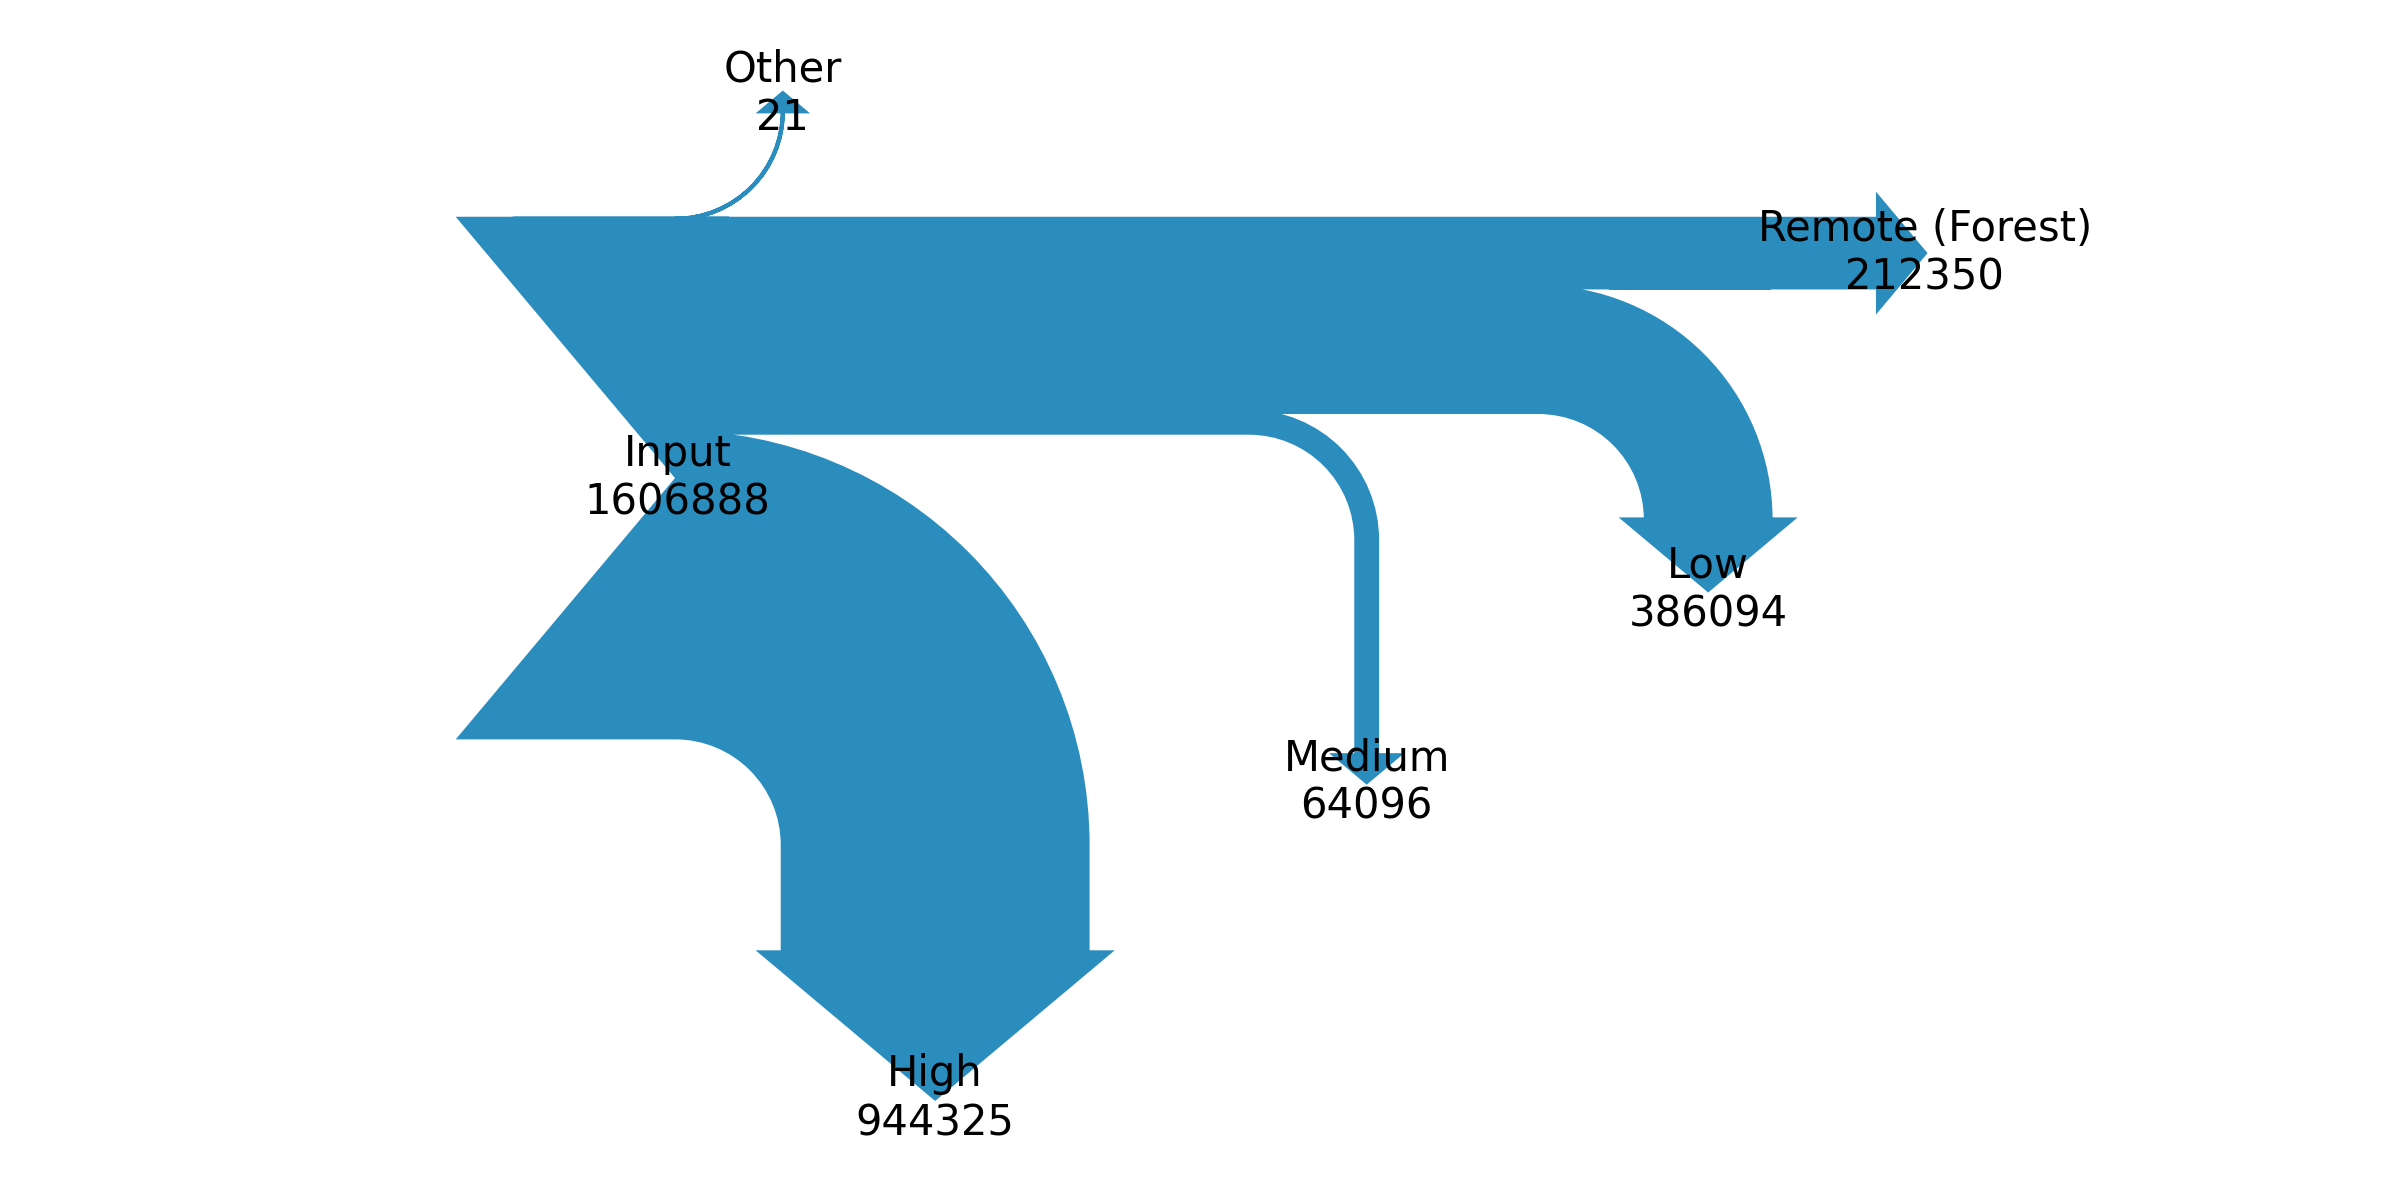

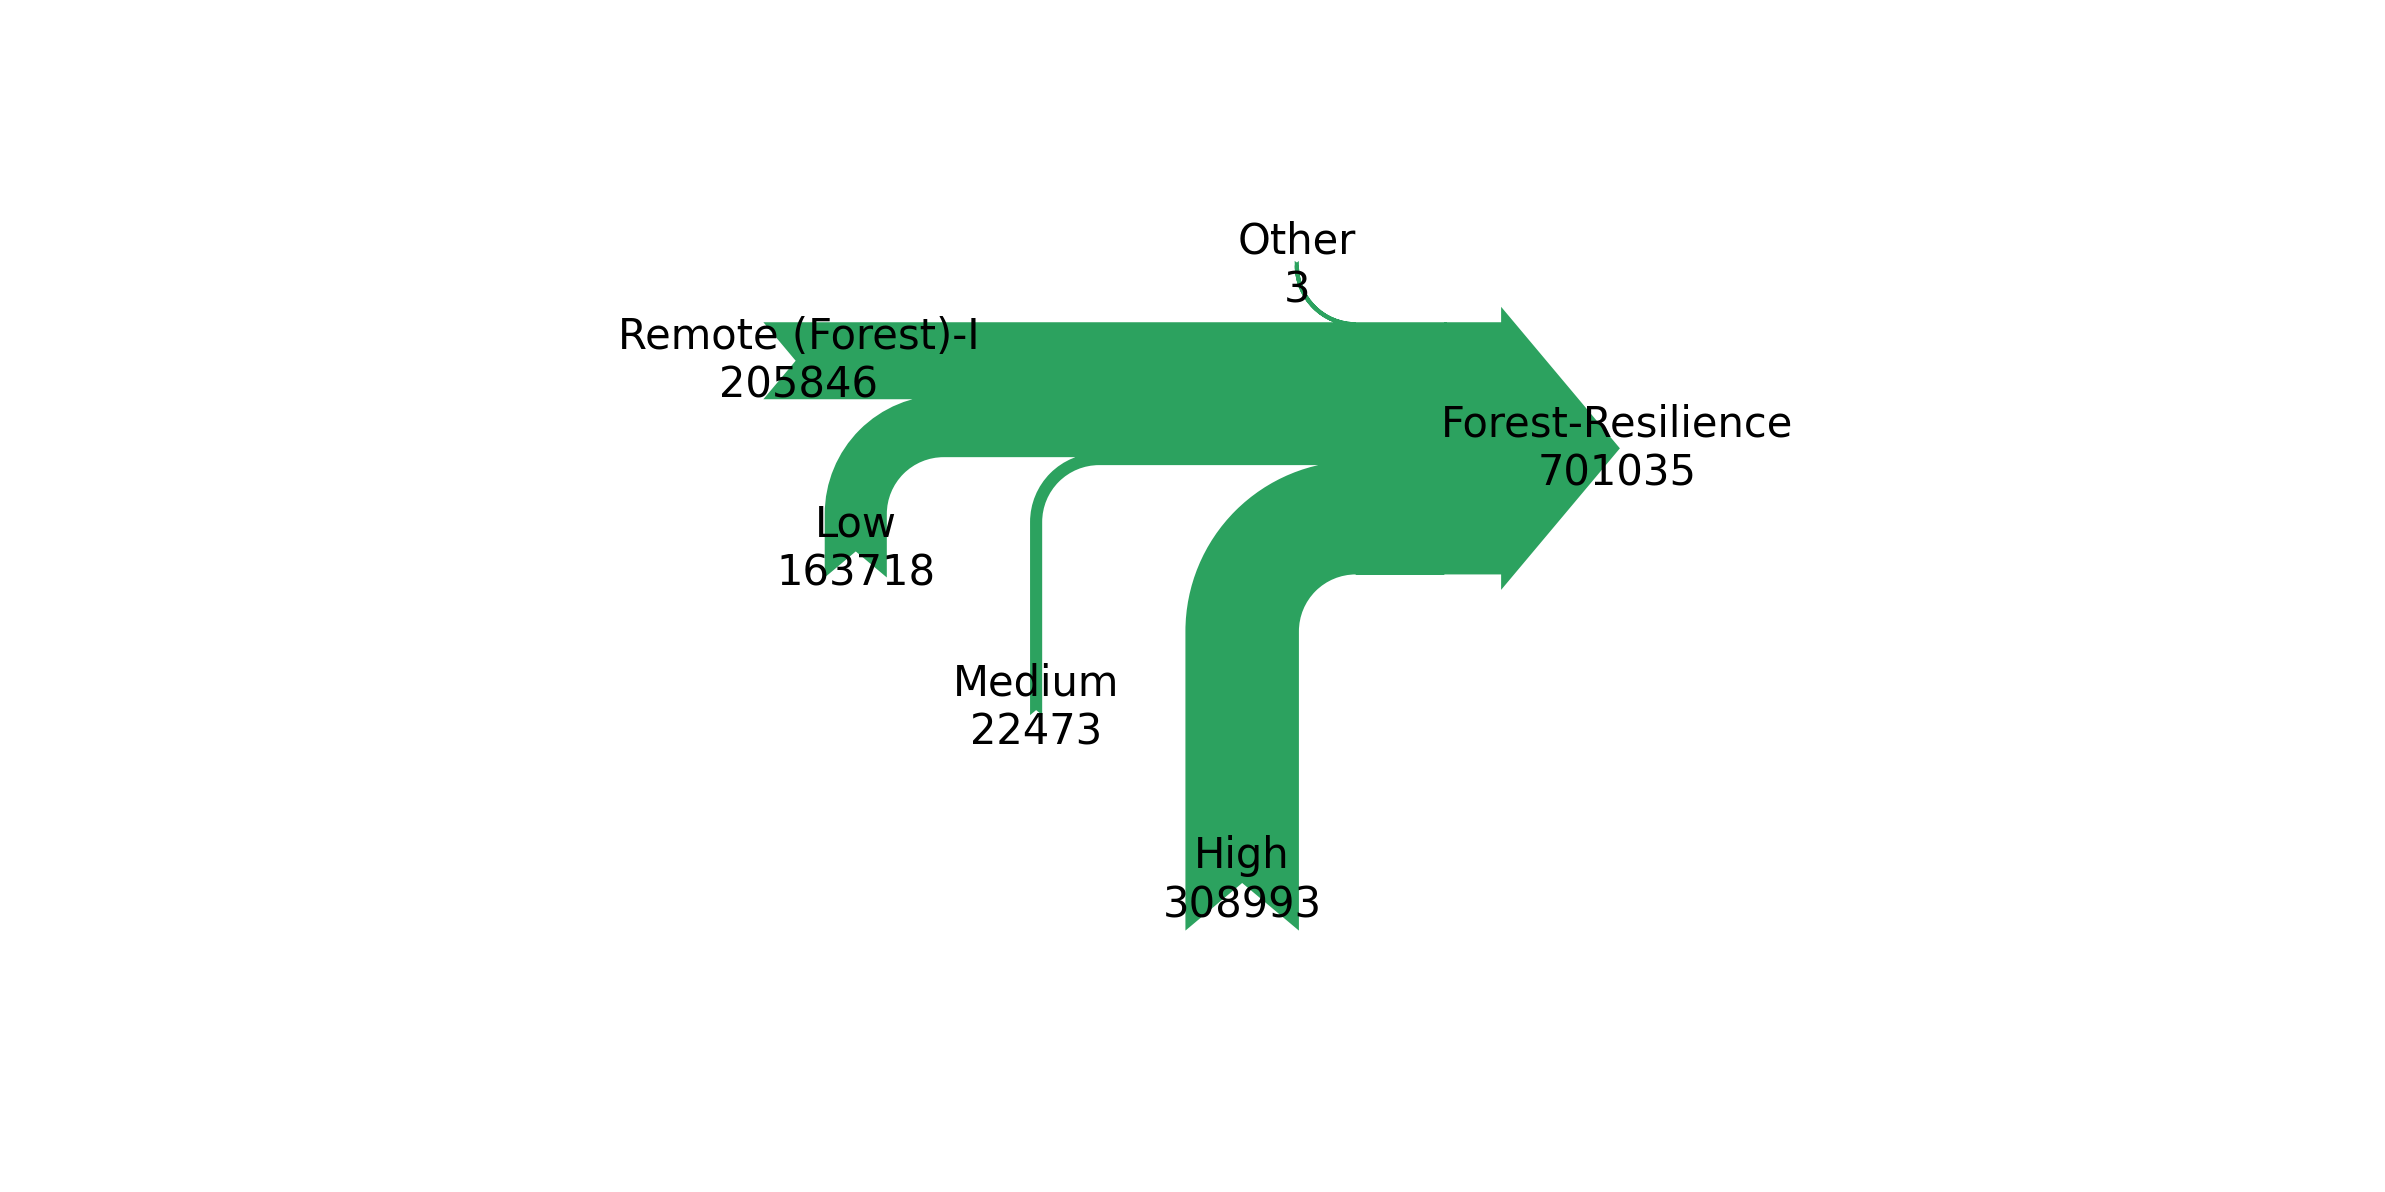

In [47]:
from matplotlib.sankey import Sankey
from matplotlib import pyplot as plt
fig = plt.figure(figsize = [10,5], dpi = 300)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000003, 
                offset= 0,
                format = '%d',shoulder = 0.02)

sankey.add(flows=a, 
           labels = ['Input', 'Low', 'Medium', 'High', 'Remote (Forest)', 'Other'], 
           orientations=[0, -1, -1, -1, 0, 1],#arrow directions,
           pathlengths = [0.05,0.1,0.3,0.2,0.1, 0.1],
           trunklength = 0.5,
           edgecolor = '#2b8cbe',
           facecolor = '#2b8cbe')

diagrams = sankey.finish()
for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()

fig = plt.figure(figsize = [10,5], dpi = 300)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000006, 
                offset= 0,
                format = '%d',shoulder = 0.02)

sankey.add(flows=b, 
           labels = ['Low', 'Medium', 'High', 'Remote (Forest)-I', 'Other', 'Forest-Resilience'], 
           orientations=[-1, -1, -1, 0, 1, 0],#arrow directions,
           pathlengths = [0.2,0.42,0.6,0.1,0.1,0.1],
           trunklength = 0.5, 
           connect = (4,3),
           edgecolor = '#2ca25f',
           facecolor = '#2ca25f')

diagrams = sankey.finish()
for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()

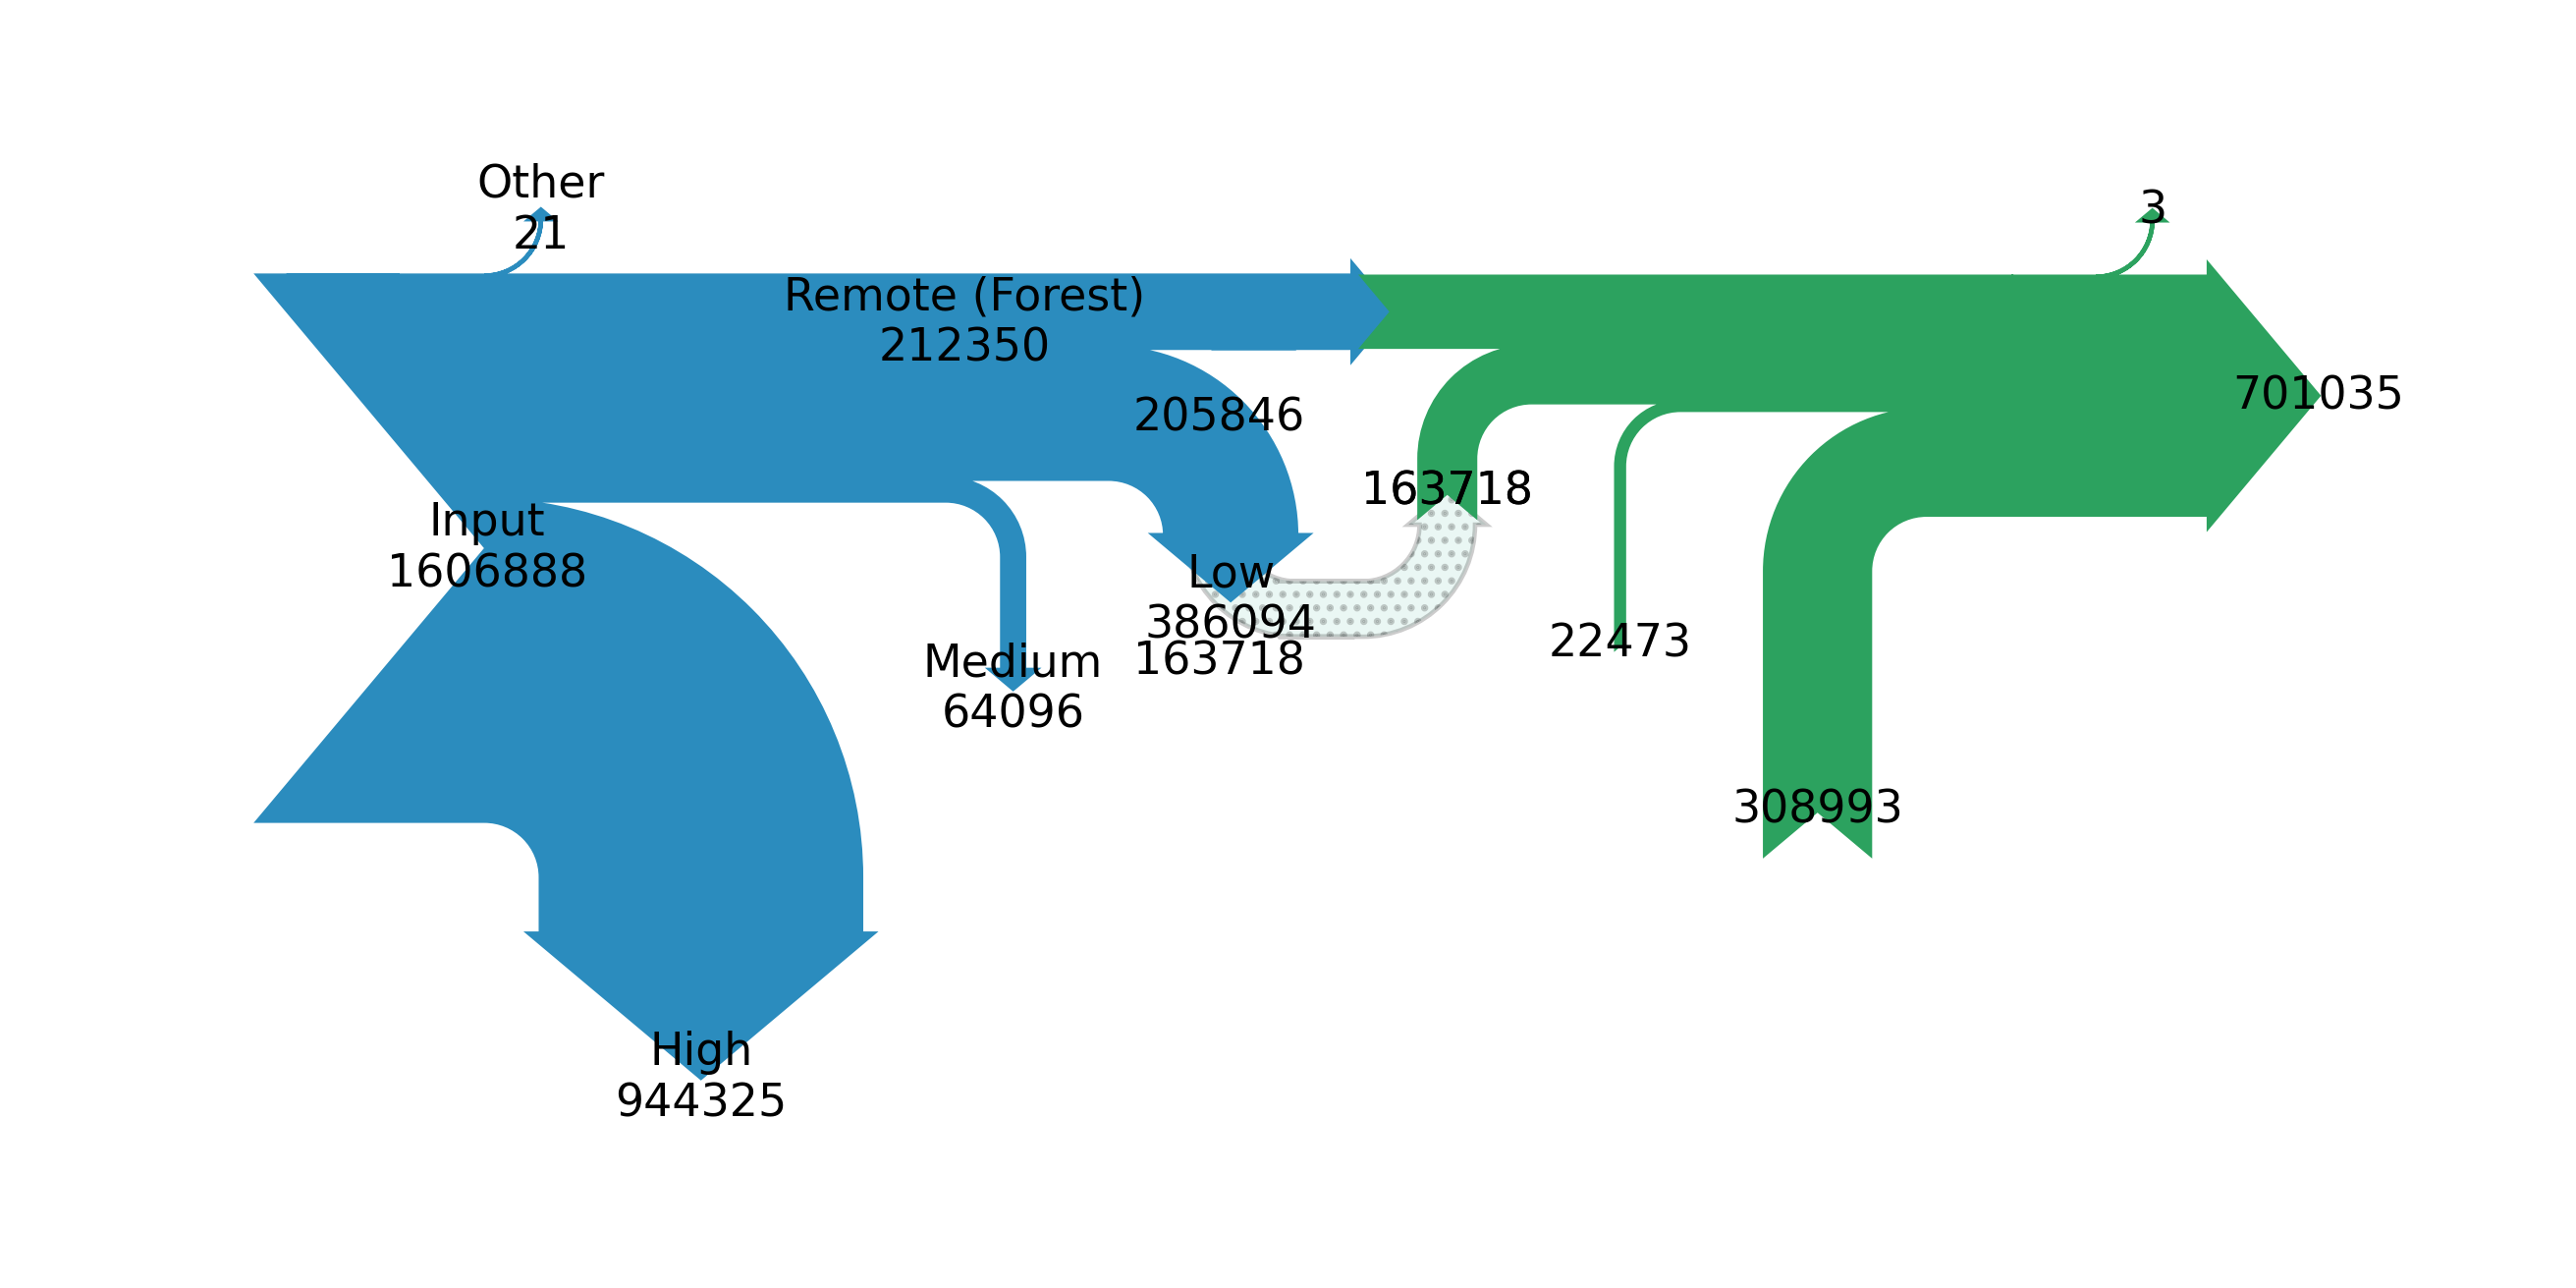

In [56]:
from matplotlib.sankey import Sankey
from matplotlib import pyplot as plt
fig = plt.figure(figsize = [10,5], dpi = 330)
ax = fig.add_subplot(1, 1, 1,)
sankey = Sankey(ax=ax, 
                scale=0.0000006, 
                offset= 0,
                format = '%d',shoulder = 0.02, tolerance=7000)

sankey.add(flows=a, 
           labels = ['Input', 'Low', 'Medium', 'High', 'Remote (Forest)', 'Other'], 
           orientations=[0, -1, -1, -1, 0, 1],#arrow directions,
           pathlengths = [0.05,0.1,0.3,0.2,0.1, 0.1],
           trunklength = 0.7,
           edgecolor = '#2b8cbe',
           facecolor = '#2b8cbe')

sankey.add(flows=b, 
           #labels = ['Low', 'Medium', 'High', 'Remote (Forest)-I', 'Other', 'Forest-Resilience'], 
           orientations=[-1, -1, -1, 0, 1, 0],#arrow directions,
           pathlengths = [0.2,0.42,0.6,0.1,0.1,0.1],
           trunklength = 0.5, 
           prior =0, connect = (4,3),
           edgecolor = '#2ca25f',
           facecolor = '#2ca25f')

sankey.add(flows=[b[0],-b[0]], 
           #labels = ['Low'], 
           orientations=[1, 1],#arrow directions,
           pathlengths = [0.1,0.1],
           trunklength = 0.32, 
           prior = 1, connect = (0,1),
           edgecolor = None,
           facecolor = '#99d8c9', hatch = '....', zorder = -2, label = 'False', alpha = 0.2)

diagrams = sankey.finish()
diagrams[0].texts[4].set_position(xy=[1.1, 0.4])
diagrams[1].texts[3].set_position(xy=[1.55, 0.23])
diagrams[2].texts[0].set_position(xy=[1.55,-0.2])

for diagram in diagrams:
    for text in diagram.texts:
        text.set_fontsize(10);
plt.axis("off") 
plt.show()